# Etapa 6 · Destilação: o que o aluno aprende com cada professor

| | |
|---|---|
| **Pergunta** | Quanto o aluno aprende só com os rótulos de cada professor, e quanto os logits acrescentam? |
| **Entrada** | `entregas/01_dados/` (os pedidos), `entregas/04b_intencao/` (a rede, a receita de treino e o teto), `entregas/05a_professor_fechado/` e `entregas/05b_professor_aberto/` (os rótulos, os logits e as respostas dos dois professores) e os treinos gravados pelos comandos de `especialista/experimentos/etapa6.py`. |
| **Entrega** | `entregas/06_destilacao/`: os alunos treinados (3 sementes cada), as respostas deles em `dev` e no teste, cada comparação pareada e a decisão do que segue para a poda. |
| **Pronto quando** | (1) cada sistema treinado tem 3 sementes, com a rede e a receita da Etapa 4b; (2) nenhum rótulo humano entrou no treino nem na parada dos alunos; (3) a temperatura do aluno B2 e o que segue para a poda saíram de `dev`, pelas regras escritas antes; (4) cada comparação é pareada, com intervalo de 95%, no teste; (5) os modelos entregues reproduzem as respostas do teste. |

**O que é destilar.** Um modelo grande e caro (o professor) resolve a tarefa. Um modelo pequeno (o aluno) aprende a imitá-lo, e é o pequeno que vai para produção. Aqui os professores são as duas LLMs da Etapa 5, e o aluno é a rede do zero da Etapa 3, com 4,9 milhões de parâmetros.

**Artigos de apoio**

- A técnica, o alvo suave e a temperatura: Hinton et al., *Distilling the Knowledge in a Neural Network* ([arXiv 1503.02531](https://arxiv.org/abs/1503.02531)).
- Destilação de LLMs com acesso só aos rótulos (caixa-preta) e com acesso aos logits (caixa-branca): Xu et al., *A Survey on Knowledge Distillation of Large Language Models* ([arXiv 2402.13116](https://arxiv.org/abs/2402.13116)).
- Uma LLM destilada num classificador pequeno, com muitas classes e poucos rótulos: Di Palo et al., *Performance-Guided LLM Knowledge Distillation for Efficient Text Classification at Scale* ([arXiv 2411.05045](https://arxiv.org/abs/2411.05045)).
- O workflow que serve de esqueleto ao projeto: Ni et al., *From Large to Super-Tiny* ([arXiv 2504.13471](https://arxiv.org/abs/2504.13471)).
- Destilar para uma rede pequena sem pré-treino, pelos logits: Tang et al., *Distilling Task-Specific Knowledge from BERT into Simple Neural Networks* ([arXiv 1903.12136](https://arxiv.org/abs/1903.12136)).
- Imitar o professor e acertar não são a mesma coisa: Stanton et al., *Does Knowledge Distillation Really Work?* ([arXiv 2106.05945](https://arxiv.org/abs/2106.05945)).
- Professor mais preciso nem sempre é professor melhor: Cho & Hariharan, *On the Efficacy of Knowledge Distillation* ([arXiv 1910.01348](https://arxiv.org/abs/1910.01348)).
- Um aluno pode passar do professor (lá, com aluno e professor da mesma arquitetura): Furlanello et al., *Born Again Neural Networks* ([arXiv 1805.04770](https://arxiv.org/abs/1805.04770)).
- Redes aprendem o sinal mesmo com muitos rótulos errados: Rolnick et al., *Deep Learning is Robust to Massive Label Noise* ([arXiv 1705.10694](https://arxiv.org/abs/1705.10694)).
- Suavização de rótulos e destilação: Müller et al., *When Does Label Smoothing Help?* ([arXiv 1906.02629](https://arxiv.org/abs/1906.02629)).
- Calibração: Guo et al., *On Calibration of Modern Neural Networks* ([arXiv 1706.04599](https://arxiv.org/abs/1706.04599)).
- Variação entre sementes: Reimers & Gurevych ([arXiv 1707.09861](https://arxiv.org/abs/1707.09861)).

**Roteiro**

1. O cenário e os sistemas
2. O que ficou decidido antes de medir
3. Como o aluno aprende com os logits
4. Os treinos
5. A temperatura do aluno B2
6. Os sistemas no teste
7. As comparações
8. O aluno imita o professor?
9. O que segue para a poda
10. Entrega
11. Resposta

In [1]:
import json
import shutil
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator

from especialista import visual
from especialista.avaliacao import confianca, eficiencia, qualidade, resultados
from especialista.avaliacao.previsao import Previsao, carregar_previsoes, ouro, salvar_previsoes
from especialista.caminhos import ENTREGAS, RAIZ, entrega
from especialista.dados import massive
from especialista.experimentos import etapa6
from especialista.modelos.diet import Config, SistemaDiet
from especialista.treino import Receita

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 200)
torch.set_num_threads(1)

PASTA = entrega("06_destilacao")
SEMENTES = etapa6.SEMENTES
TEMPERATURAS = etapa6.TEMPERATURAS
FECHADO, ABERTO = (etapa6.PROFESSORES[p]["nome"] for p in ("fechado", "aberto"))

particoes, rotulos = massive.carregar_entrega()
treino, dev, teste = (particoes[p] for p in ("train", "dev", "test"))
intents = rotulos["intents"]
coluna = {intent: i for i, intent in enumerate(intents)}
ouro_treino, ouro_dev, ouro_teste = ouro(treino), ouro(dev), ouro(teste)
gabarito = {"dev": ouro_dev, "test": ouro_teste}
TRES = ("intent_acc", "slot_f1", "exact_match")   # as três métricas das leituras


def n(x):
    return f"{int(x):,}".replace(",", ".")


def num(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")


def pts(x, casas=1):
    return num(100 * x, casas)


def dif(x):
    return f"{100 * x:+.1f}".replace(".", ",").replace("-", "−")


def com_intervalo(linha):
    return f"{dif(linha['diferenca'])} ({dif(linha['ic_min'])} a {dif(linha['ic_max'])})"


def valor_com_intervalo(linha):
    return f"{pts(linha['valor'])} ({pts(linha['ic_min'])} a {pts(linha['ic_max'])})"


def posicao(linha):
    """Onde B fica em relação a A numa comparação pareada B − A."""
    return "acima" if linha["ic_min"] > 0 else "abaixo" if linha["ic_max"] < 0 else "sem diferença distinguível"


def tres_posicoes(tabela):
    """A leitura de uma comparação nas três métricas, em uma frase."""
    return (f"{posicao(tabela.loc['intent_acc'])} em intenção ({com_intervalo(tabela.loc['intent_acc'])}), "
            f"{posicao(tabela.loc['slot_f1'])} em entidades ({com_intervalo(tabela.loc['slot_f1'])}) e "
            f"{posicao(tabela.loc['exact_match'])} em exact match ({com_intervalo(tabela.loc['exact_match'])})")


def trio(tabela, coluna_do_valor="valor"):
    """Valor e intervalo de uma linha de tabela, em pontos percentuais, para os gráficos."""
    return tuple(100 * tabela[c] for c in (coluna_do_valor, "ic_min", "ic_max"))


def diferencas(dados, titulo, eixo_x):
    """`visual.diferencas_com_intervalo`, com o número das diferenças negativas à esquerda da barra.

    À direita, o número de uma diferença negativa pequena ficaria em cima da linha do zero.
    """
    fig, ax = visual.diferencas_com_intervalo(dados, titulo, eixo_x)
    for anotacao, (valor, minimo, maximo) in zip(ax.texts, dados.values()):
        if valor < 0:
            anotacao.xy = (minimo, anotacao.xy[1])
            anotacao.set_position((-7, 0))
            anotacao.set_ha("right")
    return fig, ax

## 1. O cenário e os sistemas

**O cenário.** Uma equipe tem um assistente virtual e 11.514 pedidos de usuários guardados. Só 299 deles têm rótulo humano. Ela quer um modelo pequeno, que responda em milissegundos, e não tem como rotular o resto à mão. Duas LLMs viram os 299 exemplos e rotularam os 11.514 pedidos: uma fechada, pela API (Etapa 5a), e uma aberta, na placa de vídeo da máquina (Etapa 5b). A aberta entrega também a probabilidade que deu a cada uma das 60 intenções.

Cinco sistemas, todos com **a mesma rede e a mesma receita de treino** (as da Etapa 4b). O que muda de um para o outro é só de onde vêm os rótulos do treino. Um sexto treino serve de controle para ler o aluno B2 (seção 2, item 6):

In [2]:
demonstracoes = pd.read_parquet(ENTREGAS / etapa6.DEMONSTRACOES)
rotulado = {p: etapa6.treino_do_professor(p, treino) for p in ("fechado", "aberto")}             # o treino com os rótulos de cada professor
do_professor = {p: {"dev": etapa6.previsoes_do_professor(p, "dev", dev), "test": etapa6.previsoes_do_professor(p, "test", teste)}
                for p in ("fechado", "aberto")}
teto = {particao: [carregar_previsoes(ENTREGAS / "04b_intencao" / "previsoes" / f"semente_{s}_{particao}.parquet")[1] for s in SEMENTES]
        for particao in ("dev", "test")}

# Em um caso real isto não existiria: aqui o treino tem rótulos humanos, e dá para medir os rótulos de cada professor
como_previsoes = lambda tabela: [Previsao.de_tags(i, list(t)) for i, t in zip(tabela["intent"], tabela["tags"])]
dos_rotulos = {p: qualidade.avaliar(ouro_treino, como_previsoes(rotulado[p])) for p in rotulado}
com_rotulo = {p: rotulado[p]["valido"].to_numpy() for p in rotulado}

NOME = {
    "teto": f"Teto ({n(len(treino))} rótulos humanos)",
    "piso": f"Piso ({len(demonstracoes)} rótulos humanos)",
    "fechado": f"{FECHADO} (professor fechado)",
    "A": f"Aluno A (rótulos do {FECHADO})",
    "aberto": f"{ABERTO} (professor aberto)",
    "B1": f"Aluno B1 (rótulos do {ABERTO})",
    "B1s": "Aluno B1 sem suavização de rótulos (controle)",
    "B2": f"Aluno B2 (logits do {ABERTO})",
}
CURTO = {"teto": "Teto", "piso": "Piso", "fechado": FECHADO, "A": "Aluno A", "aberto": ABERTO, "B1": "Aluno B1", "B1s": "B1 sem suavização", "B2": "Aluno B2"}
CONTROLE = "aluno_b1_sem_suavizacao"
PROFESSOR_DE = {"A": "fechado", "B1": "aberto", "B2": "aberto"}

humano = lambda quantos: {"exemplos de treino": n(quantos), "intenção igual à humana nos rótulos": "100", "pedido inteiro igual ao humano": "100"}
de_professor = lambda p: {"exemplos de treino": n(com_rotulo[p].sum()), "intenção igual à humana nos rótulos": pts(dos_rotulos[p]["intent_acc"]),
                          "pedido inteiro igual ao humano": pts(dos_rotulos[p]["exact_match"])}
pd.DataFrame([
    {"sistema": "Teto", "treina com": "rótulos humanos de todos os pedidos", **humano(len(treino)), "situação": "já treinado na Etapa 4b"},
    {"sistema": "Piso do cenário", "treina com": f"só os {len(demonstracoes)} rótulos humanos", **humano(len(demonstracoes)), "situação": "treinado aqui"},
    {"sistema": "Aluno A", "treina com": f"rótulos do professor fechado ({FECHADO})", **de_professor("fechado"), "situação": "treinado aqui"},
    {"sistema": "Aluno B1", "treina com": f"rótulos do professor aberto ({ABERTO})", **de_professor("aberto"), "situação": "treinado aqui"},
    {"sistema": "Aluno B2", "treina com": "entidades dos rótulos do professor aberto; intenção pelos logits dele, com temperatura", **de_professor("aberto"),
     "situação": f"treinado aqui, em {len(TEMPERATURAS)} temperaturas"},
    {"sistema": "Controle do B2", "treina com": "o mesmo do aluno B1, sem a suavização de rótulos", **de_professor("aberto"), "situação": "treinado aqui"},
]).set_index("sistema")

,treina com,exemplos de treino,intenção igual à humana nos rótulos,pedido inteiro igual ao humano,situação
sistema,,,,,
Teto,rótulos humanos de todos os pedidos,11.514,100,100,já treinado na Etapa 4b
Piso do cenário,só os 299 rótulos humanos,299,100,100,treinado aqui
Aluno A,rótulos do professor fechado (Claude Haiku 5.5),11.514,"84,2","53,6",treinado aqui
Aluno B1,rótulos do professor aberto (Qwen3-8B),11.503,"77,8","43,6",treinado aqui
Aluno B2,"entidades dos rótulos do professor aberto; intenção pelos logits dele, com temperatura",11.503,"77,8","43,6","treinado aqui, em 4 temperaturas"
Controle do B2,"o mesmo do aluno B1, sem a suavização de rótulos",11.503,"77,8","43,6",treinado aqui


In [3]:
sem_rotulo = {p: int((~com_rotulo[p]).sum()) for p in rotulado}
display(Markdown(f"""
**Leitura.**

- As duas colunas do meio dizem **com que material cada aluno estuda**. Dos pedidos rotulados pelo {FECHADO}, {pts(dos_rotulos['fechado']['exact_match'])}% estão inteiramente iguais aos rótulos humanos; dos rotulados pelo {ABERTO}, {pts(dos_rotulos['aberto']['exact_match'])}%. Em cada 100 pedidos, o aluno A estuda cerca de {num(100 * (1 - dos_rotulos['fechado']['exact_match']), 0)} com algum erro, e os alunos B, cerca de {num(100 * (1 - dos_rotulos['aberto']['exact_match']), 0)}.
- Pedidos sem rótulo aproveitável (a resposta da LLM não pôde ser lida): {n(sem_rotulo['fechado'])} do professor fechado e {n(sem_rotulo['aberto'])} do aberto. Ficam fora do treino do aluno correspondente.
- O **teto** diz até onde a rede chega com todos os rótulos humanos. O **piso** diz até onde ela chega com o que a equipe tem sem nenhuma LLM. Os alunos ficam em algum ponto entre os dois; a etapa mede onde.
"""))


**Leitura.**

- As duas colunas do meio dizem **com que material cada aluno estuda**. Dos pedidos rotulados pelo Claude Haiku 5.5, 53,6% estão inteiramente iguais aos rótulos humanos; dos rotulados pelo Qwen3-8B, 43,6%. Em cada 100 pedidos, o aluno A estuda cerca de 46 com algum erro, e os alunos B, cerca de 56.
- Pedidos sem rótulo aproveitável (a resposta da LLM não pôde ser lida): 0 do professor fechado e 11 do aberto. Ficam fora do treino do aluno correspondente.
- O **teto** diz até onde a rede chega com todos os rótulos humanos. O **piso** diz até onde ela chega com o que a equipe tem sem nenhuma LLM. Os alunos ficam em algum ponto entre os dois; a etapa mede onde.


## 2. O que ficou decidido antes de medir

Cada decisão abaixo foi escrita, e posta no código, antes de qualquer treino desta etapa.

**1. Nenhum rótulo humano entra no treino de um aluno.** No cenário, a equipe só tem 299 rótulos, e eles já foram gastos nos exemplos que a LLM vê. Hinton et al. chamam os dados em que o aluno aprende de conjunto de transferência, e notam que ele pode ser inteiro sem rótulo: quem rotula é o professor. Isso vale aqui para as duas partes do treino:

- os **rótulos do treino** são os do professor, em todos os pedidos;
- a **época de parada** é escolhida no `dev` rotulado pelo mesmo professor. O laço de treino mede, a cada 5 épocas, o exact match do aluno contra as respostas do professor em `dev`, e fica com o melhor ponto.

Os rótulos humanos de `dev` só aparecem nas decisões de análise deste notebook (a temperatura do aluno B2, o que segue para a poda), e os do teste só no resultado.

**2. Rótulos puros do professor.** O aluno treina com o rótulo do professor também nos 299 pedidos que têm rótulo humano. Assim cada aluno mede uma coisa só: o que dá para aprender daquele professor. Pedidos sem rótulo aproveitável ficam fora.

**3. Uma mudança por linha.** A rede, a receita (80 épocas, suavização de rótulos de 0,1, média móvel dos pesos) e as 3 sementes são as da Etapa 4b para todos. O vocabulário de features dos alunos sai dos 11.514 pedidos, que a equipe tem sem rótulo; é o mesmo do teto.

**4. O piso.** Treina só com os 299 exemplos, e o vocabulário de features dele sai só desses exemplos (um feature nunca visto no treino ficaria com o vetor do sorteio inicial, que é ruído). A época de parada do piso usa o `dev` humano, como a do teto. É uma vantagem que o cenário não daria ao piso, e ela joga contra os alunos na comparação.

**5. O aluno B2 aprende a intenção pelos logits.** A perda de intenção deixa de comparar o aluno com um rótulo e passa a comparar a distribuição do aluno com a do professor, as duas com temperatura T (Hinton et al., seção 2):

$$L_\text{intenção} = T^2 \cdot \mathrm{KL}\big(\,\mathrm{softmax}(z_\text{professor}/T)\;\|\;\mathrm{softmax}(z_\text{aluno}/T)\,\big)$$

- **Sem termo de rótulo rígido.** O artigo soma um segundo termo, com o rótulo certo, quando ele existe. Aqui não existe rótulo certo no treino: o único rótulo rígido é a intenção mais provável do próprio professor, que já está dentro da distribuição. Somá-lo só deixaria o alvo mais concentrado, e isso a grade de temperaturas já cobre. O peso do rótulo rígido fica em zero.
- **Sem suavização de rótulos.** A suavização mistura o rótulo com a distribuição uniforme (Müller et al.). No B2 o alvo já é uma distribuição, a do professor, e misturá-la com a uniforme apagaria parte do que se quer aproveitar. É o cuidado que a Etapa 4b deixou anotado.
- **Grade de 4 temperaturas: 1, 2, 4 e 8.** Com T = 1 o aluno vê as probabilidades do professor como elas são. A Etapa 5b mediu que elas são confiantes demais e que uma temperatura maior as aproxima do acerto real; a seção 3 refaz essa medida com os logits entregues. A grade cobre os dois lados dessa temperatura.
- As **entidades** do B2 vêm dos mesmos rótulos do B1. A LLM não tem uma probabilidade por palavra do pedido.

**6. O controle do B2.** Do B1 para o B2 mudam duas coisas na perda de intenção: entram os logits e sai a suavização de rótulos. Se o B2 ficar diferente do B1, não dá para saber qual das duas foi. Por isso há um treino a mais, o **aluno B1 sem suavização**: mesmos rótulos do B1, suavização em zero. Com ele, cada diferença muda uma coisa só:

| Comparação | O que muda |
|---|---|
| Aluno B2 − aluno B1 sem suavização | só os logits |
| Aluno B1 − aluno B1 sem suavização | só a suavização de rótulos |
| Aluno B2 − aluno B1 | as duas coisas: a receita de logits contra a receita de rótulos da Etapa 4b |

**7. A regra da temperatura** (em `etapa6.escolher_temperatura`). Fica a temperatura de maior acurácia de intenção em `dev`, com os rótulos humanos, na média das 3 sementes; os logits só falam de intenção. Empate exato: a de maior exact match e, depois, a menor temperatura. Só a temperatura escolhida é medida no teste.

**8. As comparações**, todas pareadas, na média de 3 sementes, com intervalo de 95% (`qualidade.comparar_grupos`). Uma diferença só vale quando o intervalo não contém zero.

| Comparação | O que ela responde |
|---|---|
| Cada aluno − o seu professor | Quanto se perde (ou se ganha) ao trocar a LLM pelo aluno? |
| Aluno A − teto | Quanto custa não ter os 11.514 rótulos humanos? |
| Aluno A − piso, aluno B1 − piso | A LLM acrescenta algo aos 299 rótulos, pelo caminho do aluno? |
| Aluno B2 − aluno B1 sem suavização | Quanto valem os logits, sozinhos? |
| Aluno B2 − aluno B1 | Quanto vale trocar a receita de rótulos pela de logits? |
| Aluno A − aluno B1 | Quanto pesa a qualidade do professor? |

**9. Fidelidade.** Além do acerto contra os rótulos humanos, mede-se em que parte dos pedidos o aluno dá a mesma resposta do professor. Stanton et al. mostram que as duas medidas andam separadas: um aluno pode generalizar bem sem imitar o professor de perto.

**10. A regra do que segue para a poda** (em `etapa6.quem_segue`), decidida em `dev` com os rótulos humanos:

1. O aluno A segue: é o único do cenário em que o professor só entrega rótulos.
2. Do professor aberto segue um aluno só. É o B2 se a acurácia de intenção dele for distinguivelmente maior que a do B1 e o exact match não for distinguivelmente menor. Senão é o B1, que é mais simples: não precisa dos logits.
3. O principal, que a Etapa 7 poda primeiro, é o de maior exact match entre os que seguem.

O B1 da regra é o da receita da Etapa 4b, com suavização. O controle não concorre: ele explica de onde vem a diferença, não escolhe o modelo.

**11. Como ler os resultados.** Se o aluno A não ficar acima do piso, destilar não se justifica: os 299 rótulos sozinhos davam o mesmo. A literatura não garante que o aluno fique abaixo do professor: redes aprendem o sinal mesmo com muitos rótulos errados (Rolnick et al.), e há alunos que passam do professor (Furlanello et al.). Também não garante que o professor mais preciso dê o melhor aluno (Cho & Hariharan).

## 3. Como o aluno aprende com os logits

Para cada pedido do treino, o professor aberto deixou 60 números: o log da probabilidade de cada intenção. O rótulo rígido guarda só qual deles é o maior. A temperatura decide quanto do resto o aluno enxerga: os 60 números são divididos por T antes de virarem probabilidades.

Um pedido do treino em que o professor hesitou:

In [4]:
logits_treino = etapa6.logits_do_professor("treino", len(treino), intents)
validos = com_rotulo["aberto"]
do_rotulo = np.array([coluna.get(i, 0) for i in rotulado["aberto"]["intent"]])
# a intenção do rótulo do professor é a de maior pontuação (as pontuações foram gravadas com 4 casas)
no_topo = logits_treino[np.arange(len(treino)), do_rotulo] >= logits_treino.max(axis=1) - 1e-4
rotulo_no_topo = no_topo[validos]

certa_treino = np.array([coluna[i] for i in treino["intent"]])
professor_erra = validos & (do_rotulo != certa_treino)
prob = {T: confianca.probabilidades(logits_treino / T) for T in TEMPERATURAS}

# o exemplo: o professor erra, a intenção certa é a segunda colocada e ele não estava seguro
segunda = np.argsort(-logits_treino, axis=1)[:, 1]
candidatos = np.flatnonzero(professor_erra & no_topo & (segunda == certa_treino))
if len(candidatos) == 0:
    candidatos = np.flatnonzero(validos)
exemplo = int(candidatos[np.argmin(np.abs(prob[1][candidatos].max(axis=1) - 0.6))])
maiores = np.argsort(-logits_treino[exemplo])[:4]
print("Pedido:               ", treino.iloc[exemplo].utt)
print("Rótulo humano:        ", treino.iloc[exemplo].intent)
print("Rótulo do professor:  ", rotulado["aberto"].iloc[exemplo].intent)
print("\nProbabilidade que o aluno B2 recebe como alvo, em cada temperatura (%):")
pd.DataFrame(
    {f"T = {T}": [pts(prob[T][exemplo, i]) for i in maiores] + [pts(1 - prob[T][exemplo, maiores].sum())] for T in TEMPERATURAS},
    index=[intents[i] for i in maiores] + [f"as outras {len(intents) - len(maiores)} intenções, somadas"],
)

Pedido:                que exemplos há de cozinha típica picante
Rótulo humano:         cooking_recipe
Rótulo do professor:   cooking_query

Probabilidade que o aluno B2 recebe como alvo, em cada temperatura (%):


,T = 1,T = 2,T = 4,T = 8
cooking_query,"59,9","47,9","33,3","15,6"
cooking_recipe,"36,3","37,3","29,4","14,7"
recommendation_locations,"3,7","11,9","16,6","11,0"
news_query,"0,1","1,6","6,1","6,7"
"as outras 56 intenções, somadas","0,0","1,3","14,5","51,9"


O aluno B1 recebe só a primeira linha, como se fosse 100%. O aluno B2 recebe a coluna inteira da temperatura em que treina.

Agora em todos os pedidos do treino. A tabela mostra o que a temperatura faz com o alvo, e a última coluna refaz, em `dev`, a medida de calibração da Etapa 5b: quando o professor diz 90%, acerta 90% das vezes?

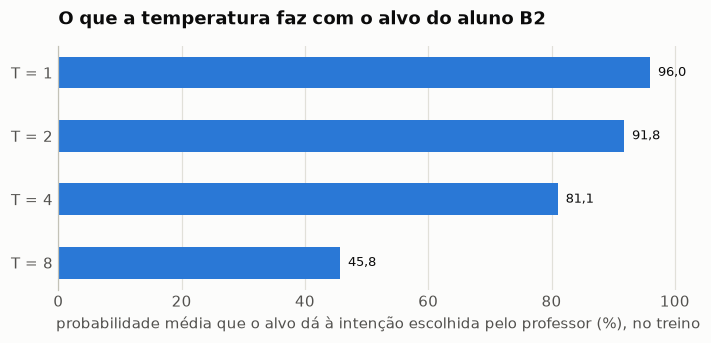

,probabilidade média na intenção escolhida,"probabilidade média na intenção certa, quando o professor erra",intenções com mais de 1% de probabilidade (média),entropia mediana (bits),erro de calibração em dev (pontos)
temperatura,,,,,
1,"96,0%","3,9%","1,3","0,00","18,5"
2,"91,8%","6,8%","1,9","0,01","14,3"
4,"81,1%","9,6%","4,0","0,53","3,3"
8,"45,8%","8,4%","14,5","3,43","32,0"


In [5]:
logits_dev = etapa6.logits_do_professor("dev", len(dev), intents)
certa_dev = np.array([coluna[o.intent] for o in ouro_dev])
acertou_dev = logits_dev.argmax(axis=1) == certa_dev

linhas, ece = [], {}
for T in TEMPERATURAS:
    p, p_dev = prob[T][validos], confianca.probabilidades(logits_dev / T)
    ece[T] = confianca.erro_de_calibracao(confianca.faixas_de_confianca(p_dev.max(axis=1), acertou_dev))
    linhas.append({
        "temperatura": T,
        "probabilidade média na intenção escolhida": p.max(axis=1).mean(),
        "probabilidade média na intenção certa, quando o professor erra": prob[T][professor_erra, certa_treino[professor_erra]].mean(),
        "intenções com mais de 1% de probabilidade (média)": (p > 0.01).sum(axis=1).mean(),
        "entropia mediana (bits)": float(np.median(confianca.entropia(p))),
        "erro de calibração em dev (pontos)": ece[T],
    })
alvo = pd.DataFrame(linhas).set_index("temperatura")

fig, ax = visual.barras_em_ordem(
    {f"T = {T}": 100 * alvo.loc[T, "probabilidade média na intenção escolhida"] for T in TEMPERATURAS},
    "O que a temperatura faz com o alvo do aluno B2", "probabilidade média que o alvo dá à intenção escolhida pelo professor (%), no treino",
)
visual.salvar(fig, PASTA, "alvo_por_temperatura")
plt.show()

alvo.assign(**{
    "probabilidade média na intenção escolhida": alvo["probabilidade média na intenção escolhida"].map(lambda v: pts(v) + "%"),
    "probabilidade média na intenção certa, quando o professor erra": alvo["probabilidade média na intenção certa, quando o professor erra"].map(lambda v: pts(v) + "%"),
    "intenções com mais de 1% de probabilidade (média)": alvo["intenções com mais de 1% de probabilidade (média)"].map(lambda v: num(v, 1)),
    "entropia mediana (bits)": alvo["entropia mediana (bits)"].map(lambda v: num(v, 2)),
    "erro de calibração em dev (pontos)": alvo["erro de calibração em dev (pontos)"].map(pts),
})

In [6]:
T_calibrada = min(ece, key=ece.get)
primeira, ultima = TEMPERATURAS[0], TEMPERATURAS[-1]
display(Markdown(f"""
**Leitura.**

- A intenção do rótulo do professor é a de maior pontuação em {pts(rotulo_no_topo.mean(), 2)}% dos pedidos com rótulo: os logits e os rótulos contam a mesma história, e o que os logits têm a mais é o resto da distribuição.
- O professor aberto erra a intenção em {n(professor_erra.sum())} dos {n(validos.sum())} pedidos do treino com rótulo ({pts(professor_erra.sum() / validos.sum())}%). Nesses pedidos, o alvo do aluno B1 não tem nada da intenção certa. O do B2 dá a ela, em média, {", ".join(f"{pts(alvo.loc[T, 'probabilidade média na intenção certa, quando o professor erra'])}% com T = {T}" for T in TEMPERATURAS)}.
- A temperatura cobra um preço: com T = {ultima}, em média {num(alvo.loc[ultima, 'intenções com mais de 1% de probabilidade (média)'], 1)} intenções recebem mais de 1% de probabilidade, contra {num(alvo.loc[primeira, 'intenções com mais de 1% de probabilidade (média)'], 1)} com T = {primeira}. Parte disso é informação (intenções parecidas), parte é ruído das pontuações mais baixas. Hinton et al. notam o mesmo: temperaturas menores dão menos atenção aos logits muito negativos, que são os menos confiáveis.
- Em `dev`, a temperatura que deixa a confiança do professor mais perto do acerto é T = {T_calibrada} (erro de calibração de {pts(ece[T_calibrada])} pontos; com T = 1, {pts(ece[1])}).
"""))


**Leitura.**

- A intenção do rótulo do professor é a de maior pontuação em 100,00% dos pedidos com rótulo: os logits e os rótulos contam a mesma história, e o que os logits têm a mais é o resto da distribuição.
- O professor aberto erra a intenção em 2.540 dos 11.503 pedidos do treino com rótulo (22,1%). Nesses pedidos, o alvo do aluno B1 não tem nada da intenção certa. O do B2 dá a ela, em média, 3,9% com T = 1, 6,8% com T = 2, 9,6% com T = 4, 8,4% com T = 8.
- A temperatura cobra um preço: com T = 8, em média 14,5 intenções recebem mais de 1% de probabilidade, contra 1,3 com T = 1. Parte disso é informação (intenções parecidas), parte é ruído das pontuações mais baixas. Hinton et al. notam o mesmo: temperaturas menores dão menos atenção aos logits muito negativos, que são os menos confiáveis.
- Em `dev`, a temperatura que deixa a confiança do professor mais perto do acerto é T = 4 (erro de calibração de 3,3 pontos; com T = 1, 18,5).


## 4. Os treinos

Os treinos rodam fora do notebook, pela linha de comando (`uv run python -m especialista.experimentos.etapa6 --variante aluno_a --semente 0`), e ficam gravados em `data/execucoes/06_destilacao/`. Aqui eles só são lidos.

In [7]:
faltam = etapa6.faltam()
assert not faltam, "Faltam treinos. Rode, para cada um: uv run python -m especialista.experimentos.etapa6 --variante V --semente S. Faltam: " + ", ".join(f"{v} {s}" for v, s in faltam)
execucoes = {v: [etapa6.carregar(v, s) for s in SEMENTES] for v in etapa6.VARIANTES}
em_dev = {v: [e["previsoes_dev"] for e in es] for v, es in execucoes.items()}

# a rede e a receita de cada execução são as da Etapa 4b, com o que a variante declara trocar
partida = json.loads((ENTREGAS / etapa6.DECISAO_DA_REDE).read_text(encoding="utf-8"))
config_da_4b, receita_da_4b = Config(**partida["config"]).como_dict(), Receita(**partida["receita"]).como_dict()
como_declarado = all(
    e["meta"]["config"] == Config(**etapa6.definicao(v)["config"]).como_dict() and e["meta"]["receita"] == receita_da_4b
    for v, es in execucoes.items() for e in es
)

dev_de_parada = {p: etapa6.dev_do_professor(p, dev, intents) for p in ("fechado", "aberto")}


def no_dev_de_parada(variante, previsoes):
    """As métricas do aluno contra quem escolheu a sua época de parada, refeitas a partir das respostas gravadas."""
    professor = etapa6.VARIANTES[variante]["professor"]
    if professor is None:
        return qualidade.avaliar(ouro_dev, previsoes)
    fica = dev_de_parada[professor]["valido"].to_numpy()
    return qualidade.avaliar([p for p, f in zip(do_professor[professor]["dev"], fica) if f], [p for p, f in zip(previsoes, fica) if f])


linhas_dos_treinos = []
for v, es in execucoes.items():
    meta = es[0]["meta"]
    troca = {k: valor for k, valor in meta["config"].items() if config_da_4b[k] != valor}
    linhas_dos_treinos.append({
        "sistema": etapa6.VARIANTES[v]["nome"],
        "rótulos do treino": meta["origem"]["treino"].split(":")[0],
        "quem escolhe a época de parada": meta["origem"]["dev"].split(":")[0],
        "exemplos de treino": n(meta["exemplos_de_treino"]),
        "pedidos no dev de parada": n(meta["exemplos_de_dev"]),
        "o que muda na Etapa 4b": ", ".join(f"{k} = {num(valor, 1 if valor % 1 else 0)}" for k, valor in troca.items()) or "nada",
        "época escolhida (sementes 0, 1 e 2)": ", ".join(str(e["meta"]["melhor_epoca"]) for e in es),
        "exact match no dev de parada": pts(np.mean([e["meta"]["dev"]["exact_match"] for e in es])),
        "minutos por treino": num(np.mean([e["meta"]["segundos_de_treino"] for e in es]) / 60, 1),
    })
pd.DataFrame(linhas_dos_treinos).set_index("sistema")

,rótulos do treino,quem escolhe a época de parada,exemplos de treino,pedidos no dev de parada,o que muda na Etapa 4b,"época escolhida (sementes 0, 1 e 2)",exact match no dev de parada,minutos por treino
sistema,,,,,,,,
Piso do cenário (só os 299 rótulos humanos),rótulos humanos,rótulos humanos de dev,299,2.033,nada,"15, 20, 10","22,1","6,8"
Aluno A (rótulos do professor fechado),rótulos do professor fechado,rótulos do professor fechado,11.514,2.033,nada,"45, 30, 30","61,0","13,2"
Aluno B1 (rótulos do professor aberto),rótulos do professor aberto,rótulos do professor aberto,11.503,2.033,nada,"45, 45, 25","49,3","13,2"
Aluno B1 sem suavização de rótulos (controle do B2),rótulos do professor aberto,rótulos do professor aberto,11.503,2.033,suavizacao = 0,"30, 75, 25","49,3","12,2"
"Aluno B2 (logits do professor aberto, temperatura 1)",rótulos do professor aberto,rótulos do professor aberto,11.503,2.033,"suavizacao = 0, temperatura = 1","30, 80, 40","49,2","12,7"
"Aluno B2 (logits do professor aberto, temperatura 2)",rótulos do professor aberto,rótulos do professor aberto,11.503,2.033,"suavizacao = 0, temperatura = 2","80, 70, 50","49,8","12,6"
"Aluno B2 (logits do professor aberto, temperatura 4)",rótulos do professor aberto,rótulos do professor aberto,11.503,2.033,"suavizacao = 0, temperatura = 4","70, 80, 80","47,9","12,2"
"Aluno B2 (logits do professor aberto, temperatura 8)",rótulos do professor aberto,rótulos do professor aberto,11.503,2.033,"suavizacao = 0, temperatura = 8","80, 80, 80","48,3","8,8"


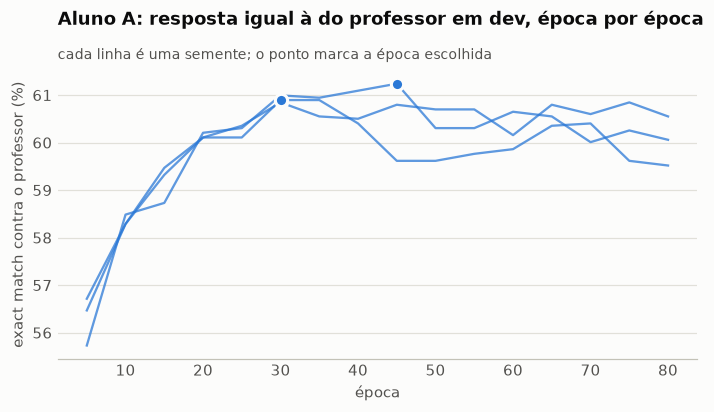


**Leitura.**

- **Sem rótulo humano no treino dos alunos:** confere. O exact match anotado em cada treino bate com a conta refeita contra os rótulos do professor (maior diferença, em pontos percentuais: 0,00). Contra os rótulos humanos o número seria outro: nos 21 treinos de alunos, a menor distância entre os dois, em pontos percentuais, é 1,0.
- **Mesma rede:** os alunos têm 4.895.834 parâmetros, os mesmos do teto. O piso tem 2.154.586: o vocabulário de features dele sai de 299 exemplos (3.786 features, contra 25.202).
- **Época de parada** (de 80, medindo a cada 5): o aluno A parou nas épocas 45, 30, 30; o aluno B1, nas épocas 45, 45, 25; o piso, nas épocas 15, 20, 10.
- **Orçamento de épocas:** Escolheram a última época, ou seja, ainda melhoravam contra o professor quando o treino acabou: Aluno B2 (logits do professor aberto, temperatura 1), 1 de 3 sementes; Aluno B2 (logits do professor aberto, temperatura 2), 1 de 3 sementes; Aluno B2 (logits do professor aberto, temperatura 4), 2 de 3 sementes; Aluno B2 (logits do professor aberto, temperatura 8), 3 de 3 sementes.


In [8]:
# Conferência: a época de cada aluno foi escolhida contra os rótulos do professor, não contra os humanos.
# O que ficou anotado no treino tem de bater com a conta refeita aqui, a partir das respostas gravadas.
alunos_treinados = [v for v in etapa6.VARIANTES if etapa6.VARIANTES[v]["professor"]]
desvio_da_parada = max(
    abs(no_dev_de_parada(v, e["previsoes_dev"])["exact_match"] - e["meta"]["dev"]["exact_match"]) for v in etapa6.VARIANTES for e in execucoes[v]
)
distancia_para_o_humano = min(
    abs(qualidade.avaliar(ouro_dev, e["previsoes_dev"])["exact_match"] - e["meta"]["dev"]["exact_match"]) for v in alunos_treinados for e in execucoes[v]
)
sem_humano = all(
    e["meta"]["origem"]["treino"].startswith("rótulos do professor") and e["meta"]["origem"]["dev"].startswith("rótulos do professor")
    for v in alunos_treinados for e in execucoes[v]
) and desvio_da_parada < 0.005

modelos_0 = {v: SistemaDiet.carregar(execucoes[v][0]["pasta"] / "modelo") for v in etapa6.VARIANTES}
modelo_do_teto = SistemaDiet.carregar(ENTREGAS / "04b_intencao" / "modelos" / "semente_0")
mesma_rede = all(modelos_0[v].parametros == modelo_do_teto.parametros for v in alunos_treinados)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for e in execucoes["aluno_a"]:
    medido = e["historico"].dropna(subset=["dev_exact_match"])
    ax.plot(medido["epoca"], 100 * medido["dev_exact_match"], color=visual.AZUL, linewidth=1.5, alpha=0.75)
    melhor = medido[medido["melhor"]]
    ax.plot(melhor["epoca"], 100 * melhor["dev_exact_match"], "o", color=visual.AZUL, markersize=8, markeredgecolor=visual.SUPERFICIE, markeredgewidth=2)
ax.set_title("Aluno A: resposta igual à do professor em dev, época por época", pad=30)
ax.text(0, 1.04, "cada linha é uma semente; o ponto marca a época escolhida", transform=ax.transAxes, fontsize=9, color=visual.TINTA_SECUNDARIA)
ax.set_xlabel("época")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_ylabel("exact match contra o professor (%)")
ax.yaxis.grid(True)
ax.yaxis.set_major_formatter(visual.VIRGULA)
ax.spines["left"].set_visible(False)
visual.salvar(fig, PASTA, "parada_do_aluno_a")
plt.show()

epocas = lambda v: [e["meta"]["melhor_epoca"] for e in execucoes[v]]
# um treino que escolhe a última época ainda melhorava quando o orçamento acabou
na_ultima = {v: sum(e["meta"]["melhor_epoca"] == receita_da_4b["epocas"] for e in es) for v, es in execucoes.items()}
if any(na_ultima.values()):
    frase_da_ultima = ("Escolheram a última época, ou seja, ainda melhoravam contra o professor quando o treino acabou: "
                       + "; ".join(f"{etapa6.VARIANTES[v]['nome']}, {q} de {len(SEMENTES)} sementes" for v, q in na_ultima.items() if q) + ".")
else:
    frase_da_ultima = "Nenhum treino escolheu a última época."
display(Markdown(f"""
**Leitura.**

- **Sem rótulo humano no treino dos alunos:** {"confere" if sem_humano else "NÃO confere"}. O exact match anotado em cada treino bate com a conta refeita contra os rótulos do professor (maior diferença, em pontos percentuais: {pts(desvio_da_parada, 2)}). Contra os rótulos humanos o número seria outro: nos {len(alunos_treinados) * len(SEMENTES)} treinos de alunos, a menor distância entre os dois, em pontos percentuais, é {pts(distancia_para_o_humano)}.
- **Mesma rede:** os alunos têm {n(modelos_0['aluno_a'].parametros)} parâmetros, {"os mesmos do teto" if mesma_rede else "DIFERENTE do teto"}. O piso tem {n(modelos_0['piso'].parametros)}: o vocabulário de features dele sai de {len(demonstracoes)} exemplos ({n(len(modelos_0['piso'].featurizador))} features, contra {n(len(modelos_0['aluno_a'].featurizador))}).
- **Época de parada** (de {receita_da_4b["epocas"]}, medindo a cada {receita_da_4b["avaliar_a_cada"]}): o aluno A parou nas épocas {", ".join(map(str, epocas("aluno_a")))}; o aluno B1, nas épocas {", ".join(map(str, epocas("aluno_b1")))}; o piso, nas épocas {", ".join(map(str, epocas("piso")))}.
- **Orçamento de épocas:** {frase_da_ultima}
"""))

## 5. A temperatura do aluno B2

Os quatro alunos B2 só diferem na temperatura. A regra (seção 2, item 7) escolhe em `dev`, com os rótulos humanos, pela acurácia de intenção.

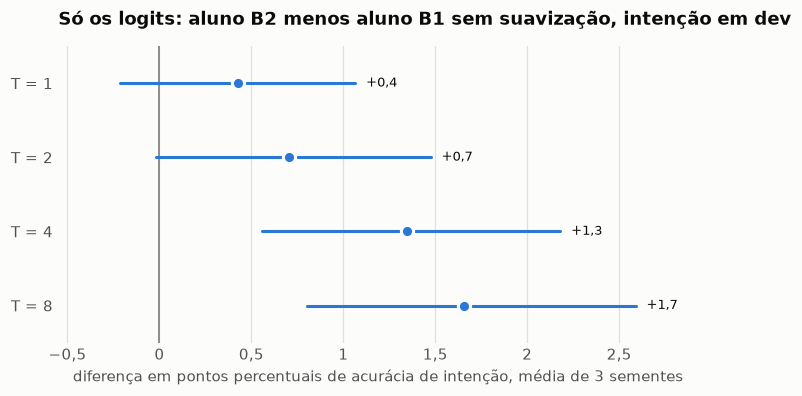

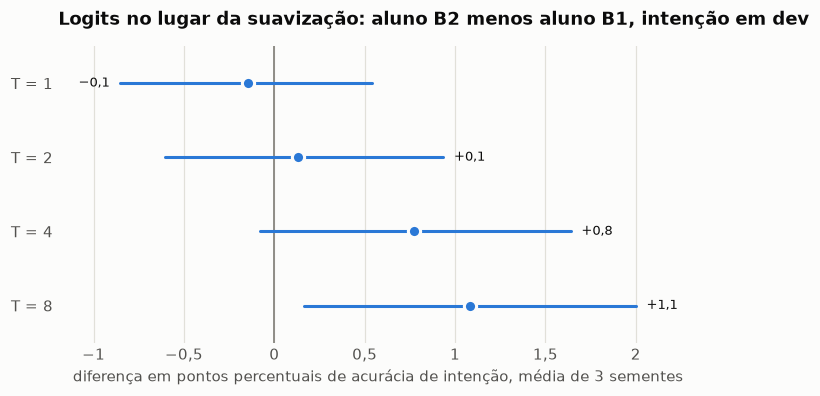

Aluno B2 em dev, contra os rótulos humanos (média de 3 sementes)


,acurácia de intenção,F1 de entidades,exact match,intenção igual à do professor,intenção: B2 − B1 sem suavização (intervalo de 95%),intenção: B2 − B1 (intervalo de 95%),exact match: B2 − B1 (intervalo de 95%),escolhida
temperatura,,,,,,,,
1,"77,1","58,8","43,9","78,5","+0,4 (−0,2 a +1,1)","−0,1 (−0,9 a +0,5)","−1,3 (−2,0 a −0,5)",
2,"77,3","59,3","44,6","79,5","+0,7 (−0,0 a +1,5)","+0,1 (−0,6 a +0,9)","−0,6 (−1,3 a +0,3)",
4,"78,0","60,4","46,3","78,9","+1,3 (+0,6 a +2,2)","+0,8 (−0,1 a +1,6)","+1,1 (+0,1 a +2,1)",
8,"78,3","60,5","46,9","79,5","+1,7 (+0,8 a +2,6)","+1,1 (+0,2 a +2,0)","+1,7 (+0,7 a +2,9)",sim


In [9]:
grupos_b2 = {T: em_dev[etapa6.variante_do_b2(T)] for T in TEMPERATURAS}
T_escolhida, medias_por_T = etapa6.escolher_temperatura(ouro_dev, grupos_b2)
B2 = etapa6.variante_do_b2(T_escolhida)
NOME["B2"] = f"Aluno B2 (logits do {ABERTO}, T = {T_escolhida})"

b2_menos_b1_dev = {T: qualidade.comparar_grupos(ouro_dev, em_dev["aluno_b1"], grupos_b2[T]) for T in TEMPERATURAS}
b2_menos_controle_dev = {T: qualidade.comparar_grupos(ouro_dev, em_dev[CONTROLE], grupos_b2[T]) for T in TEMPERATURAS}   # só os logits mudam
# o que o cenário teria para escolher, sem rótulos humanos: a concordância com o professor em dev
com_o_professor = {T: np.mean([e["meta"]["dev"]["intent_acc"] for e in execucoes[etapa6.variante_do_b2(T)]]) for T in TEMPERATURAS}
T_do_cenario = max(TEMPERATURAS, key=lambda T: (com_o_professor[T], -T))

fig, ax = diferencas(
    {f"T = {T}": trio(b2_menos_controle_dev[T].loc["intent_acc"], "diferenca") for T in TEMPERATURAS},
    "Só os logits: aluno B2 menos aluno B1 sem suavização, intenção em dev", "diferença em pontos percentuais de acurácia de intenção, média de 3 sementes",
)
visual.salvar(fig, PASTA, "temperaturas")
plt.show()

fig, ax = diferencas(
    {f"T = {T}": trio(b2_menos_b1_dev[T].loc["intent_acc"], "diferenca") for T in TEMPERATURAS},
    "Logits no lugar da suavização: aluno B2 menos aluno B1, intenção em dev", "diferença em pontos percentuais de acurácia de intenção, média de 3 sementes",
)
visual.salvar(fig, PASTA, "temperaturas_contra_b1")
plt.show()

quadro_das_temperaturas = pd.DataFrame([
    {
        "temperatura": T,
        "acurácia de intenção": pts(medias_por_T.loc[T, "intent_acc"]),
        "F1 de entidades": pts(medias_por_T.loc[T, "slot_f1"]),
        "exact match": pts(medias_por_T.loc[T, "exact_match"]),
        "intenção igual à do professor": pts(com_o_professor[T]),
        "intenção: B2 − B1 sem suavização (intervalo de 95%)": com_intervalo(b2_menos_controle_dev[T].loc["intent_acc"]),
        "intenção: B2 − B1 (intervalo de 95%)": com_intervalo(b2_menos_b1_dev[T].loc["intent_acc"]),
        "exact match: B2 − B1 (intervalo de 95%)": com_intervalo(b2_menos_b1_dev[T].loc["exact_match"]),
        "escolhida": "sim" if T == T_escolhida else "",
    }
    for T in TEMPERATURAS
]).set_index("temperatura")
print("Aluno B2 em dev, contra os rótulos humanos (média de 3 sementes)")
quadro_das_temperaturas

In [10]:
contra_as_outras = {T: qualidade.comparar_grupos(ouro_dev, grupos_b2[T], grupos_b2[T_escolhida]).loc["intent_acc"] for T in TEMPERATURAS if T != T_escolhida}
distinguiveis = [T for T, linha in contra_as_outras.items() if linha["ic_min"] > 0]
if len(distinguiveis) == len(contra_as_outras):
    frase_da_escolha = "A escolhida é distinguivelmente melhor que cada uma das outras."
elif distinguiveis:
    frase_da_escolha = (f"A escolhida só é distinguivelmente melhor que T = {', '.join(map(str, distinguiveis))}; "
                        "das demais ela não se separa, e outra amostra de `dev` poderia escolher diferente.")
else:
    frase_da_escolha = "A escolhida não é distinguivelmente melhor que nenhuma das outras: outra amostra de `dev` poderia escolher diferente."
if T_escolhida in (TEMPERATURAS[0], TEMPERATURAS[-1]):
    lado = "maior" if T_escolhida == TEMPERATURAS[-1] else "menor"
    frase_da_borda = (f"A temperatura escolhida é a {lado} da grade: daqui não dá para saber se uma temperatura ainda {lado} seria melhor. "
                      "A grade foi fixada antes de medir e não foi ampliada.")
else:
    frase_da_borda = ""
acima_de = lambda tabelas: [T for T in TEMPERATURAS if tabelas[T].loc["intent_acc", "ic_min"] > 0]
abaixo_de = lambda tabelas: [T for T in TEMPERATURAS if tabelas[T].loc["intent_acc", "ic_max"] < 0]
lista = lambda Ts: ", ".join(f"T = {T}" for T in Ts) if Ts else "nenhuma"
controle_menos_b1_dev = qualidade.comparar_grupos(ouro_dev, em_dev["aluno_b1"], em_dev[CONTROLE])

display(Markdown(f"""
**Decisão.** Fica **T = {T_escolhida}**, com {pts(medias_por_T.loc[T_escolhida, 'intent_acc'])}% de acurácia de intenção em `dev`.

- {frase_da_escolha} Diferença da escolhida para cada outra, em intenção: {"; ".join(f"T = {T}: {com_intervalo(linha)}" for T, linha in contra_as_outras.items())}.
- **Só os logits** (contra o B1 sem suavização), em intenção: ficam acima, com intervalo todo acima de zero, {lista(acima_de(b2_menos_controle_dev))}; ficam abaixo, {lista(abaixo_de(b2_menos_controle_dev))}.
- **Contra o aluno B1 como ele é**, em intenção: ficam acima, {lista(acima_de(b2_menos_b1_dev))}; ficam abaixo, {lista(abaixo_de(b2_menos_b1_dev))}.
- O controle, sozinho, contra o B1 (o que a suavização de rótulos faz quando os rótulos são do professor): {com_intervalo(controle_menos_b1_dev.loc['intent_acc'])} em intenção e {com_intervalo(controle_menos_b1_dev.loc['exact_match'])} em exact match (B1 sem suavização − B1).
- **Sem rótulos humanos**, a equipe do cenário teria de escolher pela concordância com o professor em `dev`. Essa regra escolheria T = {T_do_cenario}, {"a mesma temperatura" if T_do_cenario == T_escolhida else "outra temperatura: a escolha feita aqui usa uma informação que o cenário não tem, e isso entra nos limites"}.
""" + (f"- **Borda da grade.** {frase_da_borda}" if frase_da_borda else "")))


**Decisão.** Fica **T = 8**, com 78,3% de acurácia de intenção em `dev`.

- A escolhida só é distinguivelmente melhor que T = 1, 2; das demais ela não se separa, e outra amostra de `dev` poderia escolher diferente. Diferença da escolhida para cada outra, em intenção: T = 1: +1,2 (+0,4 a +2,1); T = 2: +1,0 (+0,1 a +1,7); T = 4: +0,3 (−0,4 a +1,0).
- **Só os logits** (contra o B1 sem suavização), em intenção: ficam acima, com intervalo todo acima de zero, T = 4, T = 8; ficam abaixo, nenhuma.
- **Contra o aluno B1 como ele é**, em intenção: ficam acima, T = 8; ficam abaixo, nenhuma.
- O controle, sozinho, contra o B1 (o que a suavização de rótulos faz quando os rótulos são do professor): −0,6 (−1,3 a +0,1) em intenção e −0,9 (−1,6 a −0,1) em exact match (B1 sem suavização − B1).
- **Sem rótulos humanos**, a equipe do cenário teria de escolher pela concordância com o professor em `dev`. Essa regra escolheria T = 8, a mesma temperatura.
- **Borda da grade.** A temperatura escolhida é a maior da grade: daqui não dá para saber se uma temperatura ainda maior seria melhor. A grade foi fixada antes de medir e não foi ampliada.

## 6. Os sistemas no teste

O teste é aberto para cinco sistemas treinados nesta etapa: o piso, o aluno A, o aluno B1, o controle (B1 sem suavização) e o aluno B2 na temperatura escolhida. As outras temperaturas do B2 não são medidas no teste.

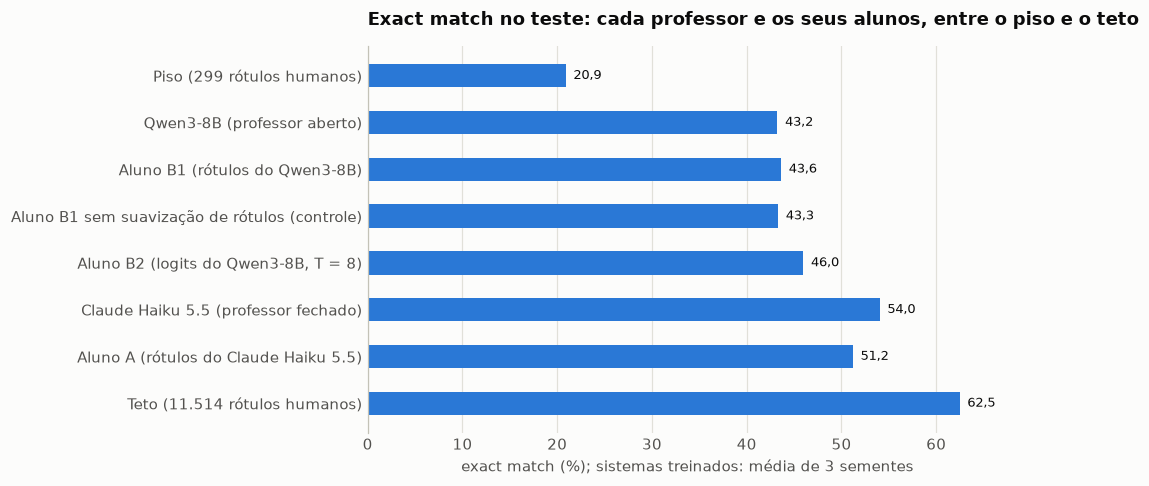

Teste, em % (intervalo de 95%). Sistemas treinados: média de 3 sementes.


,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match
Piso (299 rótulos humanos),"40,1 (38,6 a 41,5)","39,3 (37,5 a 41,1)","40,8 (39,1 a 42,4)","20,9 (19,6 a 22,2)"
Qwen3-8B (professor aberto),"77,6 (76,1 a 79,1)","76,6 (74,7 a 79,2)","55,7 (53,9 a 57,4)","43,2 (41,5 a 45,0)"
Aluno B1 (rótulos do Qwen3-8B),"76,3 (74,9 a 77,7)","74,5 (72,6 a 77,0)","57,1 (55,4 a 58,9)","43,6 (41,9 a 45,2)"
Aluno B1 sem suavização de rótulos (controle),"75,5 (74,0 a 76,9)","73,9 (72,0 a 76,4)","57,1 (55,4 a 58,8)","43,3 (41,6 a 45,0)"
"Aluno B2 (logits do Qwen3-8B, T = 8)","77,8 (76,3 a 79,3)","76,5 (74,6 a 78,7)","58,0 (56,3 a 59,8)","46,0 (44,2 a 47,6)"
Claude Haiku 5.5 (professor fechado),"83,5 (82,1 a 84,7)","82,1 (80,3 a 84,7)","66,1 (64,5 a 67,7)","54,0 (52,3 a 55,7)"
Aluno A (rótulos do Claude Haiku 5.5),"80,7 (79,4 a 82,0)","78,3 (76,4 a 80,7)","64,8 (63,2 a 66,5)","51,2 (49,6 a 52,9)"
Teto (11.514 rótulos humanos),"84,4 (83,2 a 85,6)","82,8 (81,0 a 84,8)","73,6 (72,2 a 75,1)","62,5 (60,8 a 64,1)"


In [11]:
VARIANTE_DE = {"piso": "piso", "A": "aluno_a", "B1": "aluno_b1", "B1s": CONTROLE, "B2": B2}
ENTREGUES = ("piso", "A", "B1", "B2")   # os sistemas cujos modelos vão para a entrega; do controle vão as respostas
# As respostas do teste saem na CPU, que é onde o modelo vai rodar: o resultado não depende da placa de quem reexecutar o notebook
no_teste = {
    chave: [SistemaDiet.carregar(e["pasta"] / "modelo", "cpu").prever(list(teste["utt"])) for e in execucoes[v]]
    for chave, v in VARIANTE_DE.items()
}
# cada sistema é um grupo de respostas: 3 sementes para os treinados, uma execução para cada LLM
sistemas = {
    "dev": {"teto": teto["dev"], "fechado": [do_professor["fechado"]["dev"]], "aberto": [do_professor["aberto"]["dev"]],
            **{chave: em_dev[v] for chave, v in VARIANTE_DE.items()}},
    "test": {"teto": teto["test"], "fechado": [do_professor["fechado"]["test"]], "aberto": [do_professor["aberto"]["test"]], **no_teste},
}
ORDEM = ["piso", "aberto", "B1", "B1s", "B2", "fechado", "A", "teto"]
medidas = {p: {chave: qualidade.intervalo_do_grupo(gabarito[p], sistemas[p][chave]) for chave in ORDEM} for p in ("dev", "test")}

fig, ax = visual.barras_em_ordem(
    {NOME[chave]: 100 * medidas["test"][chave].loc["exact_match", "valor"] for chave in ORDEM},
    "Exact match no teste: cada professor e os seus alunos, entre o piso e o teto", "exact match (%); sistemas treinados: média de 3 sementes",
)
visual.salvar(fig, PASTA, "todos_no_teste")
plt.show()

print("Teste, em % (intervalo de 95%). Sistemas treinados: média de 3 sementes.")
pd.DataFrame({NOME[chave]: {qualidade.NOMES[m]: valor_com_intervalo(medidas["test"][chave].loc[m]) for m in qualidade.METRICAS} for chave in ORDEM}).T

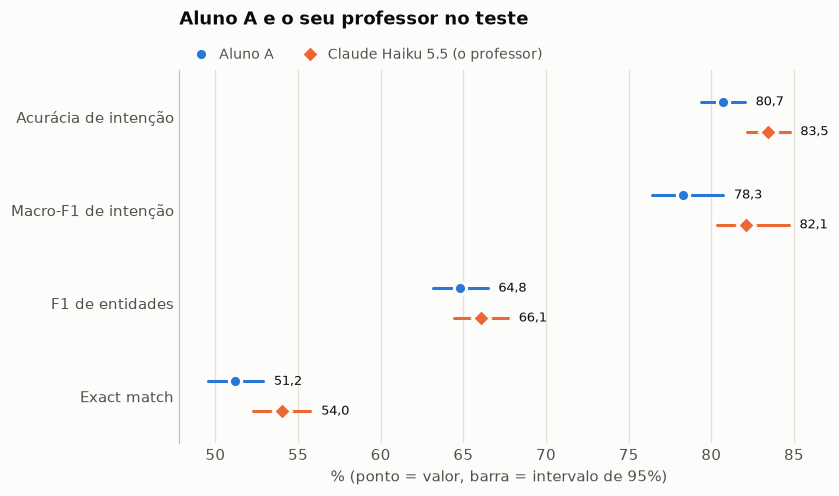

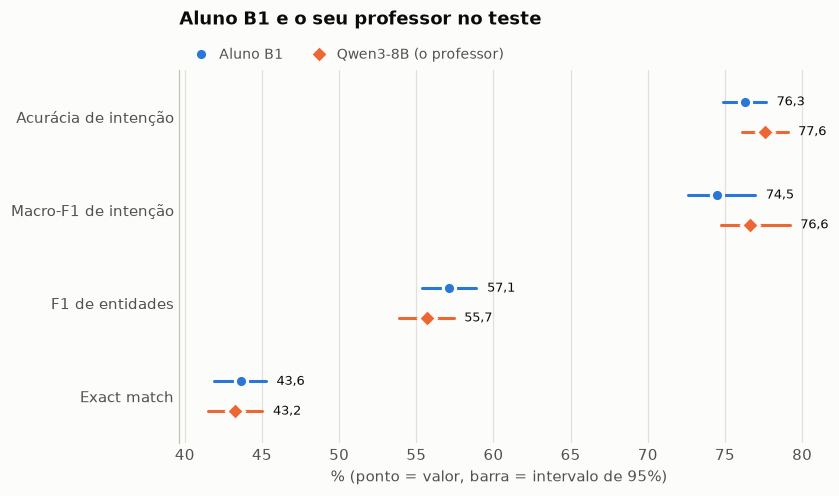

Desvio-padrão entre as 3 sementes, no teste (pontos percentuais)


,Piso,Aluno A,Aluno B1,B1 sem suavização,Aluno B2,Teto
Acurácia de intenção,"1,0","0,4","0,3","0,2","0,5","0,1"
F1 de entidades,"0,2","0,2","0,6","0,9","0,5","0,3"
Exact match,"0,9","0,2","0,8","0,3","0,3","0,4"


In [12]:
for aluno in ("A", "B1"):
    professor = PROFESSOR_DE[aluno]
    fig, ax = visual.pontos_com_intervalo(
        {
            CURTO[aluno]: {qualidade.NOMES[m]: trio(medidas["test"][aluno].loc[m]) for m in qualidade.METRICAS},
            f"{CURTO[professor]} (o professor)": {qualidade.NOMES[m]: trio(medidas["test"][professor].loc[m]) for m in qualidade.METRICAS},
        },
        f"{CURTO[aluno]} e o seu professor no teste", "% (ponto = valor, barra = intervalo de 95%)",
    )
    visual.salvar(fig, PASTA, f"aluno_{aluno.lower()}_e_professor")
    plt.show()

desvios = pd.DataFrame({CURTO[chave]: medidas["test"][chave]["desvio_sementes"] for chave in ("piso", "A", "B1", "B1s", "B2", "teto")}).loc[list(TRES)].rename(index=qualidade.NOMES)
print("Desvio-padrão entre as 3 sementes, no teste (pontos percentuais)")
desvios.map(pts)

## 7. As comparações

As comparações combinadas na seção 2, todas no teste. Cada diferença é B − A, pareada: os mesmos sorteios do conjunto de teste para os dois lados.

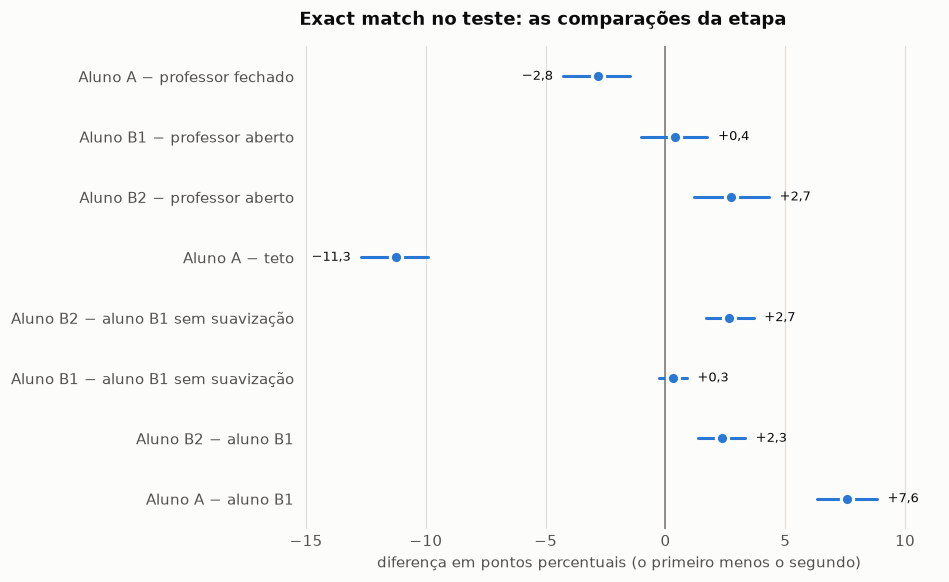

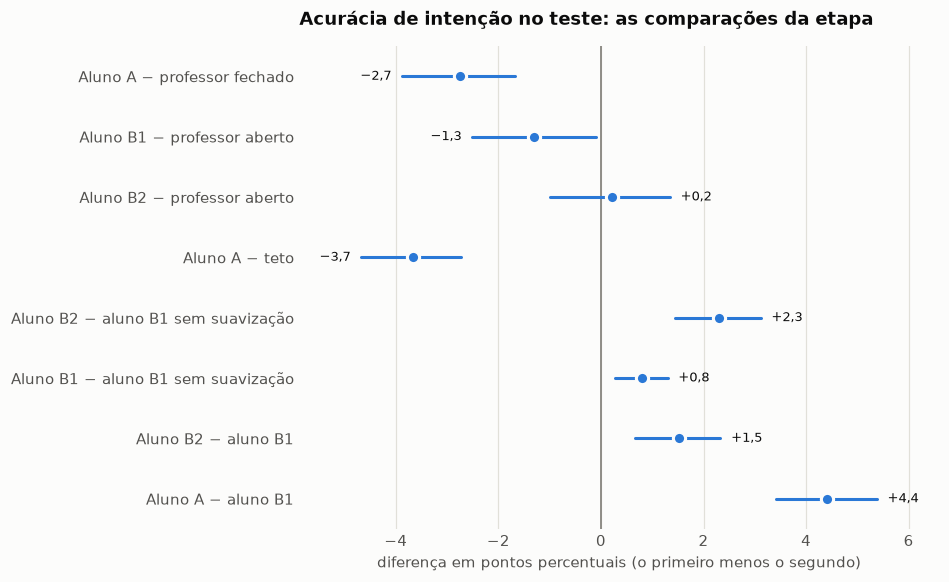

Teste: diferença em pontos percentuais (intervalo de 95%)


,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match
Aluno A − professor fechado,"−2,7 (−3,9 a −1,7)","−3,8 (−5,5 a −2,3)","−1,2 (−2,5 a −0,0)","−2,8 (−4,3 a −1,5)"
Aluno B1 − professor aberto,"−1,3 (−2,5 a −0,1)","−2,1 (−3,9 a −0,6)","+1,4 (+0,1 a +2,9)","+0,4 (−1,0 a +1,7)"
Aluno B2 − professor aberto,"+0,2 (−1,0 a +1,3)","−0,1 (−1,8 a +1,5)","+2,3 (+0,8 a +3,9)","+2,7 (+1,2 a +4,3)"
Aluno A − teto,"−3,7 (−4,7 a −2,7)","−4,5 (−6,1 a −2,9)","−8,8 (−10,1 a −7,5)","−11,3 (−12,7 a −9,9)"
Aluno A − piso,"+40,6 (+39,0 a +42,2)","+39,0 (+37,0 a +41,4)","+24,0 (+22,4 a +25,8)","+30,3 (+28,6 a +31,9)"
Aluno B1 − piso,"+36,2 (+34,6 a +37,8)","+35,2 (+33,4 a +37,4)","+16,3 (+14,7 a +18,0)","+22,7 (+21,1 a +24,3)"
Aluno B2 − aluno B1 sem suavização,"+2,3 (+1,4 a +3,1)","+2,6 (+1,6 a +3,7)","+1,0 (+0,1 a +1,8)","+2,7 (+1,7 a +3,7)"
Aluno B1 − aluno B1 sem suavização,"+0,8 (+0,3 a +1,3)","+0,6 (−0,1 a +1,3)","+0,1 (−0,5 a +0,6)","+0,3 (−0,3 a +0,9)"
Aluno B2 − aluno B1,"+1,5 (+0,7 a +2,3)","+2,0 (+1,0 a +3,1)","+0,9 (+0,0 a +1,7)","+2,3 (+1,4 a +3,3)"
Aluno A − aluno B1,"+4,4 (+3,4 a +5,4)","+3,8 (+2,5 a +5,1)","+7,7 (+6,6 a +8,9)","+7,6 (+6,3 a +8,8)"


In [13]:
COMPARACOES = {
    "Aluno A − professor fechado": ("fechado", "A"),
    "Aluno B1 − professor aberto": ("aberto", "B1"),
    "Aluno B2 − professor aberto": ("aberto", "B2"),
    "Aluno A − teto": ("teto", "A"),
    "Aluno A − piso": ("piso", "A"),
    "Aluno B1 − piso": ("piso", "B1"),
    "Aluno B2 − aluno B1 sem suavização": ("B1s", "B2"),
    "Aluno B1 − aluno B1 sem suavização": ("B1s", "B1"),
    "Aluno B2 − aluno B1": ("B1", "B2"),
    "Aluno A − aluno B1": ("B1", "A"),
}
contra = {p: {rotulo: qualidade.comparar_grupos(gabarito[p], sistemas[p][a], sistemas[p][b]) for rotulo, (a, b) in COMPARACOES.items()} for p in ("dev", "test")}
entre_professores = qualidade.comparar(ouro_teste, do_professor["aberto"]["test"], do_professor["fechado"]["test"])   # fechado − aberto

# no gráfico ficam as comparações de poucos pontos; as com o piso, de dezenas de pontos, estão na tabela e esconderiam as outras
for metrica, arquivo in (("exact_match", "comparacoes_exact_match"), ("intent_acc", "comparacoes_intencao")):
    fig, ax = diferencas(
        {rotulo: trio(tabela.loc[metrica], "diferenca") for rotulo, tabela in contra["test"].items() if "piso" not in rotulo},
        f"{qualidade.NOMES[metrica]} no teste: as comparações da etapa", "diferença em pontos percentuais (o primeiro menos o segundo)",
    )
    visual.salvar(fig, PASTA, arquivo)
    plt.show()

print("Teste: diferença em pontos percentuais (intervalo de 95%)")
pd.DataFrame({qualidade.NOMES[m]: {rotulo: com_intervalo(tabela.loc[m]) for rotulo, tabela in contra["test"].items()} for m in qualidade.METRICAS})

In [14]:
c = contra["test"]
em = lambda chave: medidas["test"][chave].loc["exact_match", "valor"]
caminho = (em("A") - em("piso")) / (em("teto") - em("piso"))   # a parte da distância do piso ao teto que o aluno A cobre
logits = c["Aluno B2 − aluno B1 sem suavização"]      # só os logits mudam
receitas = c["Aluno B2 − aluno B1"]                    # logits no lugar da suavização
suavizacao = c["Aluno B1 − aluno B1 sem suavização"]   # só a suavização muda
if logits.loc["intent_acc", "ic_min"] > 0:
    frase_dos_logits = "Os logits acrescentam: com o resto igual, a intenção do B2 fica acima, com intervalo todo acima de zero."
elif logits.loc["intent_acc", "ic_max"] < 0:
    frase_dos_logits = "Os logits atrapalham: com o resto igual, a intenção do B2 fica abaixo, com intervalo todo abaixo de zero."
else:
    frase_dos_logits = "Com o resto igual, não dá para distinguir o aluno com logits do aluno com rótulos em intenção: o intervalo contém zero."

display(Markdown(f"""
**Leitura, comparação por comparação (teste).**

1. **Cada aluno contra o seu professor.**
   - O aluno A, contra o {FECHADO}, fica {tres_posicoes(c['Aluno A − professor fechado'])}.
   - O aluno B1, contra o {ABERTO}, fica {tres_posicoes(c['Aluno B1 − professor aberto'])}.
   - O aluno B2, contra o {ABERTO}, fica {tres_posicoes(c['Aluno B2 − professor aberto'])}.
2. **O aluno A contra o teto** (o custo de não ter os {n(len(treino))} rótulos humanos): {tres_posicoes(c['Aluno A − teto'])}.
3. **Os alunos contra o piso** (o que a LLM acrescenta aos {len(demonstracoes)} rótulos).
   - O aluno A fica {tres_posicoes(c['Aluno A − piso'])}.
   - O aluno B1 fica {tres_posicoes(c['Aluno B1 − piso'])}.
   - Em exact match, o aluno A cobre {pts(caminho, 0)}% da distância entre o piso ({pts(em('piso'))}) e o teto ({pts(em('teto'))}).
4. **O valor dos logits** (aluno B2 com T = {T_escolhida}).
   - Só os logits mudam (B2 − B1 sem suavização): {tres_posicoes(logits)}. {frase_dos_logits}
   - Logits no lugar da suavização (B2 − B1): {tres_posicoes(receitas)}.
   - Só a suavização muda (B1 − B1 sem suavização): {tres_posicoes(suavizacao)}.
5. **O peso da qualidade do professor** (aluno A − aluno B1): {tres_posicoes(c['Aluno A − aluno B1'])}. Entre os dois professores a diferença é de {com_intervalo(entre_professores.loc['intent_acc'])} em intenção, {com_intervalo(entre_professores.loc['slot_f1'])} em entidades e {com_intervalo(entre_professores.loc['exact_match'])} em exact match ({FECHADO} − {ABERTO}).
"""))


**Leitura, comparação por comparação (teste).**

1. **Cada aluno contra o seu professor.**
   - O aluno A, contra o Claude Haiku 5.5, fica abaixo em intenção (−2,7 (−3,9 a −1,7)), abaixo em entidades (−1,2 (−2,5 a −0,0)) e abaixo em exact match (−2,8 (−4,3 a −1,5)).
   - O aluno B1, contra o Qwen3-8B, fica abaixo em intenção (−1,3 (−2,5 a −0,1)), acima em entidades (+1,4 (+0,1 a +2,9)) e sem diferença distinguível em exact match (+0,4 (−1,0 a +1,7)).
   - O aluno B2, contra o Qwen3-8B, fica sem diferença distinguível em intenção (+0,2 (−1,0 a +1,3)), acima em entidades (+2,3 (+0,8 a +3,9)) e acima em exact match (+2,7 (+1,2 a +4,3)).
2. **O aluno A contra o teto** (o custo de não ter os 11.514 rótulos humanos): abaixo em intenção (−3,7 (−4,7 a −2,7)), abaixo em entidades (−8,8 (−10,1 a −7,5)) e abaixo em exact match (−11,3 (−12,7 a −9,9)).
3. **Os alunos contra o piso** (o que a LLM acrescenta aos 299 rótulos).
   - O aluno A fica acima em intenção (+40,6 (+39,0 a +42,2)), acima em entidades (+24,0 (+22,4 a +25,8)) e acima em exact match (+30,3 (+28,6 a +31,9)).
   - O aluno B1 fica acima em intenção (+36,2 (+34,6 a +37,8)), acima em entidades (+16,3 (+14,7 a +18,0)) e acima em exact match (+22,7 (+21,1 a +24,3)).
   - Em exact match, o aluno A cobre 73% da distância entre o piso (20,9) e o teto (62,5).
4. **O valor dos logits** (aluno B2 com T = 8).
   - Só os logits mudam (B2 − B1 sem suavização): acima em intenção (+2,3 (+1,4 a +3,1)), acima em entidades (+1,0 (+0,1 a +1,8)) e acima em exact match (+2,7 (+1,7 a +3,7)). Os logits acrescentam: com o resto igual, a intenção do B2 fica acima, com intervalo todo acima de zero.
   - Logits no lugar da suavização (B2 − B1): acima em intenção (+1,5 (+0,7 a +2,3)), acima em entidades (+0,9 (+0,0 a +1,7)) e acima em exact match (+2,3 (+1,4 a +3,3)).
   - Só a suavização muda (B1 − B1 sem suavização): acima em intenção (+0,8 (+0,3 a +1,3)), sem diferença distinguível em entidades (+0,1 (−0,5 a +0,6)) e sem diferença distinguível em exact match (+0,3 (−0,3 a +0,9)).
5. **O peso da qualidade do professor** (aluno A − aluno B1): acima em intenção (+4,4 (+3,4 a +5,4)), acima em entidades (+7,7 (+6,6 a +8,9)) e acima em exact match (+7,6 (+6,3 a +8,8)). Entre os dois professores a diferença é de +5,9 (+4,5 a +7,2) em intenção, +10,4 (+8,9 a +11,9) em entidades e +10,8 (+9,1 a +12,4) em exact match (Claude Haiku 5.5 − Qwen3-8B).


## 8. O aluno imita o professor?

Até aqui o gabarito foram os rótulos humanos. Agora o gabarito é o **professor**: em que parte dos pedidos do teste o aluno dá a mesma resposta que ele? É a fidelidade. Ela foi o critério de parada dos alunos (em `dev`); aqui é medida no teste, que nenhum treino viu.

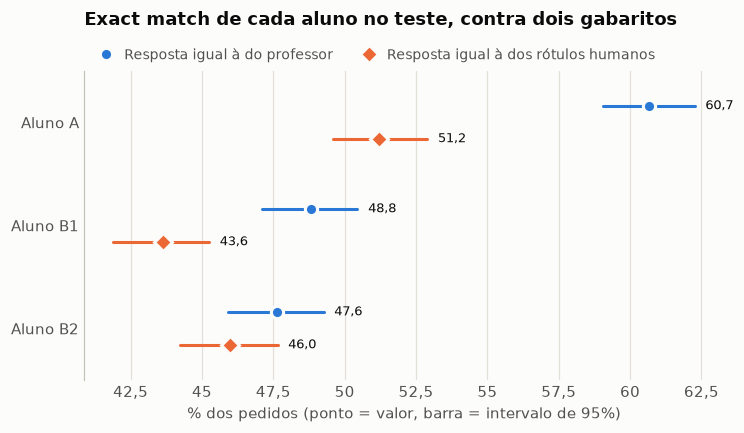

Teste, em % (intervalo de 95%), média de 3 sementes


,intenção igual à do professor,entidades iguais às do professor (F1),resposta inteira igual à do professor,resposta inteira igual à dos rótulos humanos
Aluno A (rótulos do Claude Haiku 5.5),"83,6 (82,3 a 84,8)","74,5 (73,0 a 75,9)","60,7 (59,0 a 62,3)","51,2 (49,6 a 52,9)"
Aluno B1 (rótulos do Qwen3-8B),"79,2 (77,7 a 80,5)","61,9 (60,2 a 63,4)","48,8 (47,1 a 50,4)","43,6 (41,9 a 45,2)"
"Aluno B2 (logits do Qwen3-8B, T = 8)","80,1 (78,7 a 81,5)","59,7 (58,1 a 61,4)","47,6 (45,9 a 49,3)","46,0 (44,2 a 47,6)"


In [15]:
fidelidade = {aluno: qualidade.intervalo_do_grupo(do_professor[p]["test"], sistemas["test"][aluno]) for aluno, p in PROFESSOR_DE.items()}

fig, ax = visual.pontos_com_intervalo(
    {
        "Resposta igual à do professor": {CURTO[a]: trio(fidelidade[a].loc["exact_match"]) for a in PROFESSOR_DE},
        "Resposta igual à dos rótulos humanos": {CURTO[a]: trio(medidas["test"][a].loc["exact_match"]) for a in PROFESSOR_DE},
    },
    "Exact match de cada aluno no teste, contra dois gabaritos", "% dos pedidos (ponto = valor, barra = intervalo de 95%)",
)
visual.salvar(fig, PASTA, "fidelidade")
plt.show()

print("Teste, em % (intervalo de 95%), média de 3 sementes")
pd.DataFrame({
    NOME[a]: {
        "intenção igual à do professor": valor_com_intervalo(fidelidade[a].loc["intent_acc"]),
        "entidades iguais às do professor (F1)": valor_com_intervalo(fidelidade[a].loc["slot_f1"]),
        "resposta inteira igual à do professor": valor_com_intervalo(fidelidade[a].loc["exact_match"]),
        "resposta inteira igual à dos rótulos humanos": valor_com_intervalo(medidas["test"][a].loc["exact_match"]),
    }
    for a in PROFESSOR_DE
}).T

Onde o aluno e o professor se separam. Cada pedido do teste cai em um de cinco casos, conforme quem acerta o rótulo humano. Primeiro só a intenção, depois a resposta inteira.

In [16]:
casos = {
    parte: pd.DataFrame({
        CURTO[a]: sum(etapa6.aluno_e_professor(ouro_teste, do_professor[p]["test"], previsoes, parte) for previsoes in sistemas["test"][a]) / len(SEMENTES)
        for a, p in PROFESSOR_DE.items()
    })
    for parte in ("intencao", "tudo")
}
nomes_dos_casos = {
    "os dois acertam": "Os dois acertam",
    "só o professor acerta": "Só o professor acerta (o aluno perdeu)",
    "só o aluno acerta": "Só o aluno acerta (o aluno corrigiu)",
    "erram com a mesma resposta": "Os dois erram, com a mesma resposta (o aluno copiou o erro)",
    "erram com respostas diferentes": "Os dois erram, com respostas diferentes",
}
print("Intenção: parte dos pedidos do teste em cada caso (média de 3 sementes)")
display(casos["intencao"].rename(index=nomes_dos_casos).map(lambda v: pts(v) + "%"))
print("Resposta inteira (intenção e entidades): parte dos pedidos do teste em cada caso")
display(casos["tudo"].rename(index=nomes_dos_casos).map(lambda v: pts(v) + "%"))


def frase_dos_casos(aluno, parte):
    q = casos[parte][CURTO[aluno]]
    professor_erra_ = q["só o aluno acerta"] + q["erram com a mesma resposta"] + q["erram com respostas diferentes"]
    professor_acerta = q["os dois acertam"] + q["só o professor acerta"]
    return (f"quando o professor acerta ({pts(professor_acerta)}% do teste), o aluno acerta junto em {pts(q['os dois acertam'] / professor_acerta)}% das vezes; "
            f"quando o professor erra ({pts(professor_erra_)}%), o aluno acerta em {pts(q['só o aluno acerta'] / professor_erra_)}%, "
            f"repete o mesmo erro em {pts(q['erram com a mesma resposta'] / professor_erra_)}% e erra de outro jeito em {pts(q['erram com respostas diferentes'] / professor_erra_)}%")


saldo = {a: casos["intencao"][CURTO[a]]["só o aluno acerta"] - casos["intencao"][CURTO[a]]["só o professor acerta"] for a in PROFESSOR_DE}
display(Markdown(f"""
**Leitura.**

- **Fidelidade.** O aluno A dá a resposta inteira do professor em {pts(fidelidade['A'].loc['exact_match', 'valor'])}% dos pedidos do teste; o B1, em {pts(fidelidade['B1'].loc['exact_match', 'valor'])}%; o B2, em {pts(fidelidade['B2'].loc['exact_match', 'valor'])}%. Na intenção, {pts(fidelidade['A'].loc['intent_acc', 'valor'])}%, {pts(fidelidade['B1'].loc['intent_acc', 'valor'])}% e {pts(fidelidade['B2'].loc['intent_acc', 'valor'])}%.
- **Intenção, aluno A:** {frase_dos_casos('A', 'intencao')}.
- **Intenção, aluno B1:** {frase_dos_casos('B1', 'intencao')}.
- **Intenção, aluno B2:** {frase_dos_casos('B2', 'intencao')}.
- **O saldo na intenção** (o que o aluno corrige menos o que ele perde): {dif(saldo['A'])} pontos para o aluno A, {dif(saldo['B1'])} para o B1 e {dif(saldo['B2'])} para o B2. É a mesma diferença aluno − professor da seção 7, vista por dentro.
"""))

Intenção: parte dos pedidos do teste em cada caso (média de 3 sementes)


,Aluno A,Aluno B1,Aluno B2
Os dois acertam,"76,2%","70,1%","71,0%"
Só o professor acerta (o aluno perdeu),"7,2%","7,5%","6,6%"
Só o aluno acerta (o aluno corrigiu),"4,5%","6,2%","6,8%"
"Os dois erram, com a mesma resposta (o aluno copiou o erro)","7,3%","9,0%","9,1%"
"Os dois erram, com respostas diferentes","4,7%","7,2%","6,5%"


Resposta inteira (intenção e entidades): parte dos pedidos do teste em cada caso


,Aluno A,Aluno B1,Aluno B2
Os dois acertam,"43,7%","33,8%","34,1%"
Só o professor acerta (o aluno perdeu),"10,3%","9,4%","9,2%"
Só o aluno acerta (o aluno corrigiu),"7,5%","9,8%","11,9%"
"Os dois erram, com a mesma resposta (o aluno copiou o erro)","17,0%","15,0%","13,5%"
"Os dois erram, com respostas diferentes","21,5%","31,9%","31,3%"



**Leitura.**

- **Fidelidade.** O aluno A dá a resposta inteira do professor em 60,7% dos pedidos do teste; o B1, em 48,8%; o B2, em 47,6%. Na intenção, 83,6%, 79,2% e 80,1%.
- **Intenção, aluno A:** quando o professor acerta (83,5% do teste), o aluno acerta junto em 91,3% das vezes; quando o professor erra (16,5%), o aluno acerta em 27,1%, repete o mesmo erro em 44,4% e erra de outro jeito em 28,5%.
- **Intenção, aluno B1:** quando o professor acerta (77,6% do teste), o aluno acerta junto em 90,4% das vezes; quando o professor erra (22,4%), o aluno acerta em 27,6%, repete o mesmo erro em 40,3% e erra de outro jeito em 32,1%.
- **Intenção, aluno B2:** quando o professor acerta (77,6% do teste), o aluno acerta junto em 91,5% das vezes; quando o professor erra (22,4%), o aluno acerta em 30,3%, repete o mesmo erro em 40,5% e erra de outro jeito em 29,2%.
- **O saldo na intenção** (o que o aluno corrige menos o que ele perde): −2,7 pontos para o aluno A, −1,3 para o B1 e +0,2 para o B2. É a mesma diferença aluno − professor da seção 7, vista por dentro.


## 9. O que segue para a poda

A regra da seção 2, item 10, aplicada em `dev` com os rótulos humanos.

In [17]:
segue = etapa6.quem_segue(ouro_dev, {"A": em_dev["aluno_a"], "B1": em_dev["aluno_b1"], "B2": em_dev[B2]})
b2_b1 = segue["b2_menos_b1"]
display(pd.DataFrame({
    "aluno B1": b2_b1["a"].map(pts), f"aluno B2 (T = {T_escolhida})": b2_b1["b"].map(pts),
    "B2 − B1 em dev (intervalo de 95%)": [com_intervalo(l) for _, l in b2_b1.iterrows()],
}).loc[list(qualidade.METRICAS)].rename(index=qualidade.NOMES))

display(Markdown(f"""
**Decisão.**

- Seguem para a Etapa 7: **{" e ".join(NOME[a] for a in segue["seguem"])}**.
- Do professor aberto segue o {CURTO[segue["seguem"][1]]}: em `dev`, a intenção do B2 fica {posicao(b2_b1.loc['intent_acc'])} em relação à do B1 ({com_intervalo(b2_b1.loc['intent_acc'])}) e o exact match fica {posicao(b2_b1.loc['exact_match'])} ({com_intervalo(b2_b1.loc['exact_match'])}). {"O B2 passou na regra." if segue["b2_passa"] else "O B2 não passou na regra; fica o aluno mais simples."} Contra o controle, que isola os logits, a intenção do B2 em `dev` fica {posicao(b2_menos_controle_dev[T_escolhida].loc['intent_acc'])} ({com_intervalo(b2_menos_controle_dev[T_escolhida].loc['intent_acc'])}).
- O principal é o **{CURTO[segue["principal"]]}**, com {pts(segue["exact_match_em_dev"][segue["principal"]])}% de exact match em `dev` ({"; ".join(f"{CURTO[a]}: {pts(v)}%" for a, v in segue["exact_match_em_dev"].items())}).
- No reajuste depois da poda, cada aluno continua com o sinal com que foi destilado (PLANO.md): os rótulos do seu professor{f" e, no B2, os logits com T = {T_escolhida}" if "B2" in segue["seguem"] else ""}.
"""))

,aluno B1,aluno B2 (T = 8),B2 − B1 em dev (intervalo de 95%)
Acurácia de intenção,"77,2","78,3","+1,1 (+0,2 a +2,0)"
Macro-F1 de intenção,"76,2","77,7","+1,5 (+0,2 a +2,6)"
F1 de entidades,"60,0","60,5","+0,5 (−0,5 a +1,6)"
Exact match,"45,2","46,9","+1,7 (+0,7 a +2,9)"



**Decisão.**

- Seguem para a Etapa 7: **Aluno A (rótulos do Claude Haiku 5.5) e Aluno B2 (logits do Qwen3-8B, T = 8)**.
- Do professor aberto segue o Aluno B2: em `dev`, a intenção do B2 fica acima em relação à do B1 (+1,1 (+0,2 a +2,0)) e o exact match fica acima (+1,7 (+0,7 a +2,9)). O B2 passou na regra. Contra o controle, que isola os logits, a intenção do B2 em `dev` fica acima (+1,7 (+0,8 a +2,6)).
- O principal é o **Aluno A**, com 52,0% de exact match em `dev` (Aluno A: 52,0%; Aluno B2: 46,9%).
- No reajuste depois da poda, cada aluno continua com o sinal com que foi destilado (PLANO.md): os rótulos do seu professor e, no B2, os logits com T = 8.


## 10. Entrega

Vão para a entrega os modelos do piso e dos três alunos, as respostas de todos os treinos (as do controle também), cada comparação e a decisão.

In [18]:
# 1. Modelos, respostas e históricos
for chave, v in VARIANTE_DE.items():
    for i, semente in enumerate(SEMENTES):
        salvar_previsoes(PASTA / "previsoes" / f"{v}_semente_{semente}_test.parquet", teste["id"], no_teste[chave][i])
        if chave in ENTREGUES:
            destino = PASTA / "modelos" / v / f"semente_{semente}"
            if destino.exists():
                shutil.rmtree(destino)
            shutil.copytree(execucoes[v][i]["pasta"] / "modelo", destino)
(PASTA / "historicos").mkdir(exist_ok=True)
for v, es in execucoes.items():
    for semente, e in zip(SEMENTES, es):
        salvar_previsoes(PASTA / "previsoes" / f"{v}_semente_{semente}_dev.parquet", dev["id"], e["previsoes_dev"])
        e["historico"].to_csv(PASTA / "historicos" / f"{v}_semente_{semente}.csv", index=False)

# 2. Latência e tamanho, medidos nos modelos da entrega (semente 0), em 1 núcleo de CPU, na mesma sessão que o teto
entregues = {chave: SistemaDiet.carregar(PASTA / "modelos" / VARIANTE_DE[chave] / "semente_0", "cpu") for chave in ENTREGUES}
tempos = {chave: eficiencia.medir_latencia(sistema, list(dev["utt"])) for chave, sistema in entregues.items()}
tempos["teto"] = eficiencia.medir_latencia(modelo_do_teto, list(dev["utt"]))
bytes_em_disco = {chave: sum(p.stat().st_size for p in (PASTA / "modelos" / VARIANTE_DE[chave] / "semente_0").iterdir()) for chave in ENTREGUES}
recarrega_ok = all(entregues[chave].prever(list(teste["utt"])) == no_teste[chave][0] for chave in ENTREGUES)
p50 = lambda chave: eficiencia.resumir_latencia(tempos[chave])["latencia_p50_ms"]
teto_na_4b = float(resultados.carregar(ENTREGAS / "04b_intencao").query("particao == 'test'").iloc[0]["latencia_p50_ms"])
maquina_ocupada = bool(p50("teto") > 1.2 * teto_na_4b)   # o mesmo modelo, bem mais lento que na Etapa 4b: havia outros processos na máquina

# 3. A tabela de resultados: os cinco sistemas em dev e teste; as outras temperaturas do B2 só em dev
linhas_resultado = []
for chave, v in VARIANTE_DE.items():
    for particao in ("dev", "test"):
        linhas_resultado.append(resultados.registrar_grupo(
            f"DIET do zero, {NOME[chave][0].lower() + NOME[chave][1:]}, média de {len(SEMENTES)} sementes", particao, gabarito[particao], sistemas[particao][chave],
            tempos_ms=tempos.get(chave), parametros=modelos_0[v].parametros, bytes_em_disco=bytes_em_disco.get(chave), threads=1, variante=v,
            latencia_com_a_maquina_ocupada=maquina_ocupada if chave in tempos else None,
        ))
for T in TEMPERATURAS:
    if T != T_escolhida:
        v = etapa6.variante_do_b2(T)
        linhas_resultado.append(resultados.registrar_grupo(
            f"DIET do zero, aluno B2 (logits do {ABERTO}, T = {T}), média de {len(SEMENTES)} sementes", "dev", ouro_dev, em_dev[v],
            parametros=modelos_0[v].parametros, variante=v,
        ))
resultados.salvar(linhas_resultado, PASTA)

# 4. As comparações, a grade de temperaturas e a fidelidade
pd.concat({f"{p} · {rotulo}": t.loc[list(qualidade.METRICAS)] for p in ("dev", "test") for rotulo, t in contra[p].items()},
          names=["comparacao", "metrica"]).to_csv(PASTA / "comparacoes.csv")
medias_por_T.assign(
    intencao_igual_a_do_professor=pd.Series(com_o_professor),
    b2_menos_b1_intencao=pd.Series({T: b2_menos_b1_dev[T].loc["intent_acc", "diferenca"] for T in TEMPERATURAS}),
    b2_menos_b1_ic_min=pd.Series({T: b2_menos_b1_dev[T].loc["intent_acc", "ic_min"] for T in TEMPERATURAS}),
    b2_menos_b1_ic_max=pd.Series({T: b2_menos_b1_dev[T].loc["intent_acc", "ic_max"] for T in TEMPERATURAS}),
    b2_menos_b1_sem_suavizacao_intencao=pd.Series({T: b2_menos_controle_dev[T].loc["intent_acc", "diferenca"] for T in TEMPERATURAS}),
    b2_menos_b1_sem_suavizacao_ic_min=pd.Series({T: b2_menos_controle_dev[T].loc["intent_acc", "ic_min"] for T in TEMPERATURAS}),
    b2_menos_b1_sem_suavizacao_ic_max=pd.Series({T: b2_menos_controle_dev[T].loc["intent_acc", "ic_max"] for T in TEMPERATURAS}),
    erro_de_calibracao_do_professor=pd.Series(ece),
    escolhida=[T == T_escolhida for T in medias_por_T.index],
).to_csv(PASTA / "temperaturas.csv")
pd.concat({NOME[a]: fidelidade[a].loc[list(qualidade.METRICAS)] for a in PROFESSOR_DE}, names=["aluno", "metrica"]).to_csv(PASTA / "fidelidade.csv")

# 5. A decisão: é este arquivo que a Etapa 7 lê
relativo = lambda caminho: str(caminho.relative_to(RAIZ))
decisao = {
    "etapa": "06_destilacao",
    "gerado_em": date.today().isoformat(),
    "rede_e_receita": relativo(ENTREGAS / etapa6.DECISAO_DA_REDE),
    "temperatura_do_b2": T_escolhida,
    "regra_da_temperatura": "maior acurácia de intenção em dev (rótulos humanos), média de 3 sementes; empate: maior exact match, depois menor temperatura",
    "seguem": segue["seguem"],
    "principal": segue["principal"],
    "regra_do_que_segue": ("o aluno A segue; do professor aberto segue o B2 se a intenção for distinguivelmente maior que a do B1 em dev (IC95 acima de zero) "
                           "e o exact match não for distinguivelmente menor, senão o B1; o principal é o de maior exact match em dev entre os que seguem"),
    "alunos": {
        chave: {
            "nome": NOME[chave],
            "segue": chave in segue["seguem"],
            "variante": VARIANTE_DE[chave],
            "modelos": relativo(PASTA / "modelos" / VARIANTE_DE[chave]),
            "sementes": list(SEMENTES),
            "config": execucoes[VARIANTE_DE[chave]][0]["meta"]["config"],
            "receita": execucoes[VARIANTE_DE[chave]][0]["meta"]["receita"],
            "sinal": execucoes[VARIANTE_DE[chave]][0]["meta"]["origem"],
            "exact_match_em_dev": float(medidas["dev"][chave].loc["exact_match", "valor"]),
        }
        for chave in ("A", "B1", "B2")
    },
    "referencias": {"teto": "entregas/04b_intencao/modelos", "piso": relativo(PASTA / "modelos" / "piso")},
    "controle": {
        "nome": NOME["B1s"], "variante": CONTROLE, "concorre_a_seguir": False,
        "para_que_serve": "aluno B1 sem a suavização de rótulos: B2 − controle muda só os logits",
        "previsoes": relativo(PASTA / "previsoes"),
        "exact_match_em_dev": float(medidas["dev"]["B1s"].loc["exact_match", "valor"]),
    },
}
(PASTA / "decisao.json").write_text(json.dumps(decisao, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

print("Modelos da entrega, relidos do disco, reproduzem as respostas do teste:", "sim" if recarrega_ok else "NÃO")
frase_da_latencia = (f"Latência mediana em 1 núcleo de CPU, nesta sessão: {num(p50('A'), 2)} ms no aluno A, {num(p50('B2'), 2)} ms no B2 e "
                     f"{num(p50('teto'), 2)} ms no teto, que tem a mesma rede.")
if maquina_ocupada:
    frase_da_latencia += (f" Na Etapa 4b, com a máquina livre, o teto deu {num(teto_na_4b, 2)} ms: nesta sessão havia outros processos na máquina, "
                          "e as diferenças entre os sistemas vêm dessa carga, não da rede. A referência de latência continua sendo a da Etapa 4b.")
else:
    frase_da_latencia += " As diferenças entre eles são ruído de medida."
display(Markdown(frase_da_latencia))
pd.DataFrame({
    NOME[chave]: {
        "parâmetros": n(entregues[chave].parametros),
        "tamanho em disco (MB)": num(bytes_em_disco[chave] / 1e6),
        "latência p50 (ms), 1 núcleo de CPU": num(eficiencia.resumir_latencia(tempos[chave])["latencia_p50_ms"], 2),
        "latência p95 (ms)": num(eficiencia.resumir_latencia(tempos[chave])["latencia_p95_ms"], 2),
    }
    for chave in ENTREGUES
} | {NOME["teto"] + ", medido na mesma sessão": {
    "parâmetros": n(modelo_do_teto.parametros), "tamanho em disco (MB)": "—",
    "latência p50 (ms), 1 núcleo de CPU": num(eficiencia.resumir_latencia(tempos["teto"])["latencia_p50_ms"], 2),
    "latência p95 (ms)": num(eficiencia.resumir_latencia(tempos["teto"])["latencia_p95_ms"], 2),
}}).T

Modelos da entrega, relidos do disco, reproduzem as respostas do teste: sim


Latência mediana em 1 núcleo de CPU, nesta sessão: 1,14 ms no aluno A, 1,16 ms no B2 e 1,17 ms no teto, que tem a mesma rede. As diferenças entre eles são ruído de medida.

,parâmetros,tamanho em disco (MB),"latência p50 (ms), 1 núcleo de CPU",latência p95 (ms)
Piso (299 rótulos humanos),2.154.586,"8,7","1,12","1,48"
Aluno A (rótulos do Claude Haiku 5.5),4.895.834,"19,9","1,14","1,55"
Aluno B1 (rótulos do Qwen3-8B),4.895.834,"19,9","1,13","1,55"
"Aluno B2 (logits do Qwen3-8B, T = 8)",4.895.834,"19,9","1,16","1,60"
"Teto (11.514 rótulos humanos), medido na mesma sessão",4.895.834,—,"1,17","1,56"


### Critério de pronto

In [19]:
pronto = pd.Series({
    f"Cada sistema treinado tem 3 sementes, com a rede e a receita da Etapa 4b ({len(execucoes)} variantes)":
        all(len(es) == len(SEMENTES) for es in execucoes.values()) and como_declarado and mesma_rede,
    "Nenhum rótulo humano entrou no treino nem na parada dos alunos": bool(sem_humano),
    "A temperatura do B2 e o que segue para a poda saíram de dev, pelas regras escritas antes":
        T_escolhida in TEMPERATURAS and set(segue["seguem"]) <= {"A", "B1", "B2"} and (PASTA / "decisao.json").exists(),
    f"Cada comparação é pareada, com intervalo de 95%, no teste ({len(contra['test'])} comparações)":
        len(contra["test"]) == len(COMPARACOES) and all({"ic_min", "ic_max"} <= set(t.columns) for t in contra["test"].values()),
    "Os modelos entregues reproduzem as respostas do teste": bool(recarrega_ok),
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
assert (pronto["atendido"] == "sim").all()
pronto

,atendido
"Cada sistema treinado tem 3 sementes, com a rede e a receita da Etapa 4b (8 variantes)",sim
Nenhum rótulo humano entrou no treino nem na parada dos alunos,sim
"A temperatura do B2 e o que segue para a poda saíram de dev, pelas regras escritas antes",sim
"Cada comparação é pareada, com intervalo de 95%, no teste (10 comparações)",sim
Os modelos entregues reproduzem as respostas do teste,sim


## 11. Resposta

O resumo abaixo é gerado a partir dos números calculados neste notebook e gravado em `entregas/06_destilacao/RESUMO.md`.

In [20]:
t = medidas["test"]
linha_do_sistema = lambda chave: f"| {NOME[chave]} | " + " | ".join(valor_com_intervalo(t[chave].loc[m]) for m in qualidade.METRICAS) + " |"
tabela_teste = "\n".join(linha_do_sistema(chave) for chave in ORDEM)
tabela_comparacoes = "\n".join(
    f"| {rotulo} | " + " | ".join(com_intervalo(tabela.loc[m]) for m in TRES) + " |" for rotulo, tabela in contra["test"].items()
)
tabela_temperaturas = "\n".join(
    f"| {T} | {pts(alvo.loc[T, 'probabilidade média na intenção escolhida'])}% | {pts(ece[T])} | {pts(medias_por_T.loc[T, 'intent_acc'])} | {pts(medias_por_T.loc[T, 'exact_match'])} | "
    f"{com_intervalo(b2_menos_controle_dev[T].loc['intent_acc'])} | {com_intervalo(b2_menos_b1_dev[T].loc['intent_acc'])} | {'sim' if T == T_escolhida else ''} |"
    for T in TEMPERATURAS
)
tabela_fidelidade = "\n".join(
    f"| {NOME[a]} | {valor_com_intervalo(fidelidade[a].loc['intent_acc'])} | {valor_com_intervalo(fidelidade[a].loc['exact_match'])} | "
    f"{pts(casos['intencao'][CURTO[a]]['só o aluno acerta'])}% | {pts(casos['intencao'][CURTO[a]]['só o professor acerta'])}% | {pts(casos['intencao'][CURTO[a]]['erram com a mesma resposta'])}% |"
    for a in PROFESSOR_DE
)
tabela_treinos = "\n".join(
    f"| {l['sistema']} | {l['rótulos do treino']} | {l['exemplos de treino']} | {l['quem escolhe a época de parada']} | {l['o que muda na Etapa 4b']} | {l['época escolhida (sementes 0, 1 e 2)']} |"
    for l in linhas_dos_treinos
)

a_prof, a_teto, a_piso, a_b1 = (c[k] for k in ("Aluno A − professor fechado", "Aluno A − teto", "Aluno A − piso", "Aluno A − aluno B1"))
resposta = (
    f"Só com os rótulos do professor fechado ({FECHADO}), o aluno A faz no teste {pts(t['A'].loc['intent_acc', 'valor'])}% de acurácia de intenção, "
    f"{pts(t['A'].loc['slot_f1', 'valor'])}% de F1 de entidades e {pts(t['A'].loc['exact_match', 'valor'])}% de exact match. "
    f"Contra o piso, que treina só com os {len(demonstracoes)} rótulos humanos, ele fica {tres_posicoes(a_piso)}. "
    f"Contra o seu professor, fica {tres_posicoes(a_prof)}. "
    f"Contra o teto, treinado com os {n(len(treino))} rótulos humanos, fica {tres_posicoes(a_teto)}; "
    f"em exact match, ele cobre {pts(caminho, 0)}% da distância entre o piso e o teto. "
    f"Com o professor aberto ({ABERTO}), o aluno B1 faz {pts(t['B1'].loc['intent_acc', 'valor'])}% / {pts(t['B1'].loc['slot_f1', 'valor'])}% / {pts(t['B1'].loc['exact_match', 'valor'])}%; "
    f"a diferença do aluno A para ele é de {com_intervalo(a_b1.loc['exact_match'])} pontos de exact match. "
    f"**Os logits**, com a temperatura escolhida em `dev` (T = {T_escolhida}), levam o aluno B2 a {pts(t['B2'].loc['intent_acc', 'valor'])}% de intenção. "
    f"Contra o controle, que é o B1 sem suavização de rótulos e só difere do B2 nos logits, ele fica {tres_posicoes(logits)}. {frase_dos_logits} "
    f"Contra o B1 da receita da Etapa 4b, com suavização, fica {tres_posicoes(receitas)}."
)

resumo = f"""# Etapa 6 · Destilação: resumo da entrega

**Pergunta.** Quanto o aluno aprende só com os rótulos de cada professor, e quanto os logits acrescentam?

**Resposta.** {resposta}

Seguem para a poda (Etapa 7): **{" e ".join(NOME[a] for a in segue["seguem"])}**. O principal é o {CURTO[segue["principal"]]}.

## Os sistemas

Todos têm a rede e a receita da Etapa 4b ({n(modelos_0['aluno_a'].parametros)} parâmetros nos alunos, os mesmos do teto) e 3 sementes. O que muda é de onde vêm os rótulos.

| Sistema | Rótulos do treino | Exemplos de treino | Quem escolhe a época de parada | O que muda na Etapa 4b | Época escolhida (sementes 0, 1 e 2) |
|---|---|---|---|---|---|
{tabela_treinos}

- Dos pedidos rotulados pelo {FECHADO}, {pts(dos_rotulos['fechado']['exact_match'])}% estão inteiramente iguais aos rótulos humanos; dos rotulados pelo {ABERTO}, {pts(dos_rotulos['aberto']['exact_match'])}%.
- Pedidos sem rótulo aproveitável, fora do treino: {n(sem_rotulo['fechado'])} do professor fechado e {n(sem_rotulo['aberto'])} do aberto.
- O piso tem {n(modelos_0['piso'].parametros)} parâmetros: o vocabulário de features dele sai só dos {len(demonstracoes)} exemplos.
- {frase_da_latencia}

## No teste

Em % (intervalo de 95%). Sistemas treinados: média de 3 sementes.

| Sistema | {" | ".join(qualidade.NOMES[m] for m in qualidade.METRICAS)} |
|---|---|---|---|---|
{tabela_teste}

![Todos no teste](figuras/todos_no_teste.png)

## As comparações (teste)

Diferença pareada, em pontos percentuais (intervalo de 95%). Uma diferença só vale quando o intervalo não contém zero.

| Comparação | {" | ".join(qualidade.NOMES[m] for m in TRES)} |
|---|---|---|---|
{tabela_comparacoes}

![Comparações em exact match](figuras/comparacoes_exact_match.png)

![Comparações em intenção](figuras/comparacoes_intencao.png)

- Entre os dois professores ({FECHADO} − {ABERTO}): {com_intervalo(entre_professores.loc['intent_acc'])} em intenção e {com_intervalo(entre_professores.loc['exact_match'])} em exact match.
- Do B1 para o B2 mudam duas coisas: entram os logits e sai a suavização de rótulos. O controle (B1 sem suavização) separa as duas: "B2 − B1 sem suavização" muda só os logits, e "B1 − B1 sem suavização" muda só a suavização.

## A temperatura do aluno B2 (dev)

Perda de intenção do B2: T² · KL(softmax(logits do professor / T) ‖ softmax(logits do aluno / T)), sem termo de rótulo rígido e sem suavização de rótulos (Hinton et al., arXiv 1503.02531).

| T | Probabilidade média do alvo na intenção escolhida (treino) | Erro de calibração do professor (dev, pontos) | Intenção do B2 | Exact match do B2 | Intenção: B2 − B1 sem suavização (intervalo de 95%) | Intenção: B2 − B1 (intervalo de 95%) | Escolhida |
|---|---|---|---|---|---|---|---|
{tabela_temperaturas}

![Temperaturas](figuras/temperaturas.png)

- Regra: maior acurácia de intenção em `dev`, com os rótulos humanos, na média de 3 sementes. {frase_da_escolha}
- Sem rótulos humanos, pela concordância com o professor em `dev`, a escolha seria T = {T_do_cenario}.{(" " + frase_da_borda) if frase_da_borda else ""}
- O controle (B1 sem suavização) contra o B1, em `dev`: {com_intervalo(controle_menos_b1_dev.loc['intent_acc'])} em intenção e {com_intervalo(controle_menos_b1_dev.loc['exact_match'])} em exact match.

## O aluno imita o professor? (teste)

| Aluno | Intenção igual à do professor | Resposta inteira igual à do professor | Só o aluno acerta a intenção | Só o professor acerta a intenção | Os dois erram a intenção com a mesma resposta |
|---|---|---|---|---|---|
{tabela_fidelidade}

![Fidelidade](figuras/fidelidade.png)

- Aluno A, na intenção: {frase_dos_casos('A', 'intencao')}.

## O que segue para a poda

- Regra, decidida em `dev`: o aluno A segue; do professor aberto segue o B2 se a intenção for distinguivelmente maior que a do B1 e o exact match não for distinguivelmente menor, senão o B1; o principal é o de maior exact match entre os que seguem.
- Em `dev`, B2 − B1: {com_intervalo(b2_b1.loc['intent_acc'])} em intenção e {com_intervalo(b2_b1.loc['exact_match'])} em exact match. {"O B2 passou na regra." if segue["b2_passa"] else "O B2 não passou na regra."} O B1 da regra é o da receita da Etapa 4b; o controle não concorre.
- Seguem: {", ".join(f"{CURTO[a]} ({pts(v)}% de exact match em dev)" for a, v in segue["exact_match_em_dev"].items())}. Principal: {CURTO[segue["principal"]]}.
- `decisao.json` traz, para cada aluno, onde estão os modelos, a configuração e o sinal de treino. No reajuste depois da poda, cada aluno continua com o sinal com que foi destilado.

## Limites

- **A parada não é igual para todos.** O teto e o piso escolhem a época de parada no `dev` humano; os alunos, no `dev` rotulado pelo professor. O piso recebe assim uma vantagem que o cenário não daria.
- **A temperatura do B2 foi escolhida com os rótulos humanos de `dev`**, que o cenário não tem, e entre {len(TEMPERATURAS)} tentativas; o B1 teve uma só. A comparação B2 − B1 no teste carrega essa vantagem do B2.
- **O controle veio depois da primeira versão do plano.** O B1 sem suavização (suavização de {num(config_da_4b['suavizacao'], 1)} na Etapa 4b) foi acrescentado antes de qualquer treino, para separar o efeito dos logits do efeito de tirar a suavização. Ele não tem grade nem escolha: é um treino só, com 3 sementes.
- **Os logits são só da intenção.** As entidades do B2 são as mesmas do B1.
- **Um professor de cada tipo, uma rotulagem de cada.** A variação medida é a das 3 sementes do aluno, não a do professor.
- **A receita não foi ajustada para o piso.** São as {receita_da_4b['epocas']} épocas e o balanceamento da Etapa 4b, sobre {len(demonstracoes)} exemplos.
- **O orçamento de épocas é o da Etapa 4b para todos** ({receita_da_4b['epocas']} épocas). {frase_da_ultima}{" Para esses, mais épocas poderiam dar outro resultado; o orçamento não foi aumentado para não mudar duas coisas de uma vez." if any(na_ultima.values()) else ""}
- **A fidelidade em `dev` foi o critério de parada**; por isso a fidelidade reportada é a do teste.
- **O teste já tinha sido aberto** nas etapas anteriores. Aqui ele foi aberto para cinco sistemas, com a temperatura do B2 já decidida em `dev`.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | Os alunos que seguem para a poda, o principal, a temperatura do B2, onde estão os modelos e o sinal de treino de cada um, e o controle |
| `modelos/` | Os modelos do piso, do aluno A, do B1 e do B2 na temperatura escolhida, 3 sementes cada |
| `previsoes/` | As respostas de cada treino em `dev` e, para os cinco sistemas medidos (o controle entre eles), no teste |
| `resultados.csv` | Cada sistema em `dev` e teste; as outras temperaturas do B2 só em `dev` |
| `comparacoes.csv` | Cada comparação pareada, em `dev` e teste, em todas as métricas |
| `temperaturas.csv` | A grade do aluno B2 em `dev` |
| `fidelidade.csv` | Cada aluno contra o seu professor, no teste |
| `historicos/` | Perdas e métricas no `dev` de parada, época por época, de cada treino |
| `figuras/` | Os gráficos deste notebook |
| `06_destilacao.html` | Este notebook executado, para leitura |
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 6 · Destilação: resumo da entrega

**Pergunta.** Quanto o aluno aprende só com os rótulos de cada professor, e quanto os logits acrescentam?

**Resposta.** Só com os rótulos do professor fechado (Claude Haiku 5.5), o aluno A faz no teste 80,7% de acurácia de intenção, 64,8% de F1 de entidades e 51,2% de exact match. Contra o piso, que treina só com os 299 rótulos humanos, ele fica acima em intenção (+40,6 (+39,0 a +42,2)), acima em entidades (+24,0 (+22,4 a +25,8)) e acima em exact match (+30,3 (+28,6 a +31,9)). Contra o seu professor, fica abaixo em intenção (−2,7 (−3,9 a −1,7)), abaixo em entidades (−1,2 (−2,5 a −0,0)) e abaixo em exact match (−2,8 (−4,3 a −1,5)). Contra o teto, treinado com os 11.514 rótulos humanos, fica abaixo em intenção (−3,7 (−4,7 a −2,7)), abaixo em entidades (−8,8 (−10,1 a −7,5)) e abaixo em exact match (−11,3 (−12,7 a −9,9)); em exact match, ele cobre 73% da distância entre o piso e o teto. Com o professor aberto (Qwen3-8B), o aluno B1 faz 76,3% / 57,1% / 43,6%; a diferença do aluno A para ele é de +7,6 (+6,3 a +8,8) pontos de exact match. **Os logits**, com a temperatura escolhida em `dev` (T = 8), levam o aluno B2 a 77,8% de intenção. Contra o controle, que é o B1 sem suavização de rótulos e só difere do B2 nos logits, ele fica acima em intenção (+2,3 (+1,4 a +3,1)), acima em entidades (+1,0 (+0,1 a +1,8)) e acima em exact match (+2,7 (+1,7 a +3,7)). Os logits acrescentam: com o resto igual, a intenção do B2 fica acima, com intervalo todo acima de zero. Contra o B1 da receita da Etapa 4b, com suavização, fica acima em intenção (+1,5 (+0,7 a +2,3)), acima em entidades (+0,9 (+0,0 a +1,7)) e acima em exact match (+2,3 (+1,4 a +3,3)).

Seguem para a poda (Etapa 7): **Aluno A (rótulos do Claude Haiku 5.5) e Aluno B2 (logits do Qwen3-8B, T = 8)**. O principal é o Aluno A.

## Os sistemas

Todos têm a rede e a receita da Etapa 4b (4.895.834 parâmetros nos alunos, os mesmos do teto) e 3 sementes. O que muda é de onde vêm os rótulos.

| Sistema | Rótulos do treino | Exemplos de treino | Quem escolhe a época de parada | O que muda na Etapa 4b | Época escolhida (sementes 0, 1 e 2) |
|---|---|---|---|---|---|
| Piso do cenário (só os 299 rótulos humanos) | rótulos humanos | 299 | rótulos humanos de dev | nada | 15, 20, 10 |
| Aluno A (rótulos do professor fechado) | rótulos do professor fechado | 11.514 | rótulos do professor fechado | nada | 45, 30, 30 |
| Aluno B1 (rótulos do professor aberto) | rótulos do professor aberto | 11.503 | rótulos do professor aberto | nada | 45, 45, 25 |
| Aluno B1 sem suavização de rótulos (controle do B2) | rótulos do professor aberto | 11.503 | rótulos do professor aberto | suavizacao = 0 | 30, 75, 25 |
| Aluno B2 (logits do professor aberto, temperatura 1) | rótulos do professor aberto | 11.503 | rótulos do professor aberto | suavizacao = 0, temperatura = 1 | 30, 80, 40 |
| Aluno B2 (logits do professor aberto, temperatura 2) | rótulos do professor aberto | 11.503 | rótulos do professor aberto | suavizacao = 0, temperatura = 2 | 80, 70, 50 |
| Aluno B2 (logits do professor aberto, temperatura 4) | rótulos do professor aberto | 11.503 | rótulos do professor aberto | suavizacao = 0, temperatura = 4 | 70, 80, 80 |
| Aluno B2 (logits do professor aberto, temperatura 8) | rótulos do professor aberto | 11.503 | rótulos do professor aberto | suavizacao = 0, temperatura = 8 | 80, 80, 80 |

- Dos pedidos rotulados pelo Claude Haiku 5.5, 53,6% estão inteiramente iguais aos rótulos humanos; dos rotulados pelo Qwen3-8B, 43,6%.
- Pedidos sem rótulo aproveitável, fora do treino: 0 do professor fechado e 11 do aberto.
- O piso tem 2.154.586 parâmetros: o vocabulário de features dele sai só dos 299 exemplos.
- Latência mediana em 1 núcleo de CPU, nesta sessão: 1,14 ms no aluno A, 1,16 ms no B2 e 1,17 ms no teto, que tem a mesma rede. As diferenças entre eles são ruído de medida.

## No teste

Em % (intervalo de 95%). Sistemas treinados: média de 3 sementes.

| Sistema | Acurácia de intenção | Macro-F1 de intenção | F1 de entidades | Exact match |
|---|---|---|---|---|
| Piso (299 rótulos humanos) | 40,1 (38,6 a 41,5) | 39,3 (37,5 a 41,1) | 40,8 (39,1 a 42,4) | 20,9 (19,6 a 22,2) |
| Qwen3-8B (professor aberto) | 77,6 (76,1 a 79,1) | 76,6 (74,7 a 79,2) | 55,7 (53,9 a 57,4) | 43,2 (41,5 a 45,0) |
| Aluno B1 (rótulos do Qwen3-8B) | 76,3 (74,9 a 77,7) | 74,5 (72,6 a 77,0) | 57,1 (55,4 a 58,9) | 43,6 (41,9 a 45,2) |
| Aluno B1 sem suavização de rótulos (controle) | 75,5 (74,0 a 76,9) | 73,9 (72,0 a 76,4) | 57,1 (55,4 a 58,8) | 43,3 (41,6 a 45,0) |
| Aluno B2 (logits do Qwen3-8B, T = 8) | 77,8 (76,3 a 79,3) | 76,5 (74,6 a 78,7) | 58,0 (56,3 a 59,8) | 46,0 (44,2 a 47,6) |
| Claude Haiku 5.5 (professor fechado) | 83,5 (82,1 a 84,7) | 82,1 (80,3 a 84,7) | 66,1 (64,5 a 67,7) | 54,0 (52,3 a 55,7) |
| Aluno A (rótulos do Claude Haiku 5.5) | 80,7 (79,4 a 82,0) | 78,3 (76,4 a 80,7) | 64,8 (63,2 a 66,5) | 51,2 (49,6 a 52,9) |
| Teto (11.514 rótulos humanos) | 84,4 (83,2 a 85,6) | 82,8 (81,0 a 84,8) | 73,6 (72,2 a 75,1) | 62,5 (60,8 a 64,1) |

![Todos no teste](figuras/todos_no_teste.png)

## As comparações (teste)

Diferença pareada, em pontos percentuais (intervalo de 95%). Uma diferença só vale quando o intervalo não contém zero.

| Comparação | Acurácia de intenção | F1 de entidades | Exact match |
|---|---|---|---|
| Aluno A − professor fechado | −2,7 (−3,9 a −1,7) | −1,2 (−2,5 a −0,0) | −2,8 (−4,3 a −1,5) |
| Aluno B1 − professor aberto | −1,3 (−2,5 a −0,1) | +1,4 (+0,1 a +2,9) | +0,4 (−1,0 a +1,7) |
| Aluno B2 − professor aberto | +0,2 (−1,0 a +1,3) | +2,3 (+0,8 a +3,9) | +2,7 (+1,2 a +4,3) |
| Aluno A − teto | −3,7 (−4,7 a −2,7) | −8,8 (−10,1 a −7,5) | −11,3 (−12,7 a −9,9) |
| Aluno A − piso | +40,6 (+39,0 a +42,2) | +24,0 (+22,4 a +25,8) | +30,3 (+28,6 a +31,9) |
| Aluno B1 − piso | +36,2 (+34,6 a +37,8) | +16,3 (+14,7 a +18,0) | +22,7 (+21,1 a +24,3) |
| Aluno B2 − aluno B1 sem suavização | +2,3 (+1,4 a +3,1) | +1,0 (+0,1 a +1,8) | +2,7 (+1,7 a +3,7) |
| Aluno B1 − aluno B1 sem suavização | +0,8 (+0,3 a +1,3) | +0,1 (−0,5 a +0,6) | +0,3 (−0,3 a +0,9) |
| Aluno B2 − aluno B1 | +1,5 (+0,7 a +2,3) | +0,9 (+0,0 a +1,7) | +2,3 (+1,4 a +3,3) |
| Aluno A − aluno B1 | +4,4 (+3,4 a +5,4) | +7,7 (+6,6 a +8,9) | +7,6 (+6,3 a +8,8) |

![Comparações em exact match](figuras/comparacoes_exact_match.png)

![Comparações em intenção](figuras/comparacoes_intencao.png)

- Entre os dois professores (Claude Haiku 5.5 − Qwen3-8B): +5,9 (+4,5 a +7,2) em intenção e +10,8 (+9,1 a +12,4) em exact match.
- Do B1 para o B2 mudam duas coisas: entram os logits e sai a suavização de rótulos. O controle (B1 sem suavização) separa as duas: "B2 − B1 sem suavização" muda só os logits, e "B1 − B1 sem suavização" muda só a suavização.

## A temperatura do aluno B2 (dev)

Perda de intenção do B2: T² · KL(softmax(logits do professor / T) ‖ softmax(logits do aluno / T)), sem termo de rótulo rígido e sem suavização de rótulos (Hinton et al., arXiv 1503.02531).

| T | Probabilidade média do alvo na intenção escolhida (treino) | Erro de calibração do professor (dev, pontos) | Intenção do B2 | Exact match do B2 | Intenção: B2 − B1 sem suavização (intervalo de 95%) | Intenção: B2 − B1 (intervalo de 95%) | Escolhida |
|---|---|---|---|---|---|---|---|
| 1 | 96,0% | 18,5 | 77,1 | 43,9 | +0,4 (−0,2 a +1,1) | −0,1 (−0,9 a +0,5) |  |
| 2 | 91,8% | 14,3 | 77,3 | 44,6 | +0,7 (−0,0 a +1,5) | +0,1 (−0,6 a +0,9) |  |
| 4 | 81,1% | 3,3 | 78,0 | 46,3 | +1,3 (+0,6 a +2,2) | +0,8 (−0,1 a +1,6) |  |
| 8 | 45,8% | 32,0 | 78,3 | 46,9 | +1,7 (+0,8 a +2,6) | +1,1 (+0,2 a +2,0) | sim |

![Temperaturas](figuras/temperaturas.png)

- Regra: maior acurácia de intenção em `dev`, com os rótulos humanos, na média de 3 sementes. A escolhida só é distinguivelmente melhor que T = 1, 2; das demais ela não se separa, e outra amostra de `dev` poderia escolher diferente.
- Sem rótulos humanos, pela concordância com o professor em `dev`, a escolha seria T = 8. A temperatura escolhida é a maior da grade: daqui não dá para saber se uma temperatura ainda maior seria melhor. A grade foi fixada antes de medir e não foi ampliada.
- O controle (B1 sem suavização) contra o B1, em `dev`: −0,6 (−1,3 a +0,1) em intenção e −0,9 (−1,6 a −0,1) em exact match.

## O aluno imita o professor? (teste)

| Aluno | Intenção igual à do professor | Resposta inteira igual à do professor | Só o aluno acerta a intenção | Só o professor acerta a intenção | Os dois erram a intenção com a mesma resposta |
|---|---|---|---|---|---|
| Aluno A (rótulos do Claude Haiku 5.5) | 83,6 (82,3 a 84,8) | 60,7 (59,0 a 62,3) | 4,5% | 7,2% | 7,3% |
| Aluno B1 (rótulos do Qwen3-8B) | 79,2 (77,7 a 80,5) | 48,8 (47,1 a 50,4) | 6,2% | 7,5% | 9,0% |
| Aluno B2 (logits do Qwen3-8B, T = 8) | 80,1 (78,7 a 81,5) | 47,6 (45,9 a 49,3) | 6,8% | 6,6% | 9,1% |

![Fidelidade](figuras/fidelidade.png)

- Aluno A, na intenção: quando o professor acerta (83,5% do teste), o aluno acerta junto em 91,3% das vezes; quando o professor erra (16,5%), o aluno acerta em 27,1%, repete o mesmo erro em 44,4% e erra de outro jeito em 28,5%.

## O que segue para a poda

- Regra, decidida em `dev`: o aluno A segue; do professor aberto segue o B2 se a intenção for distinguivelmente maior que a do B1 e o exact match não for distinguivelmente menor, senão o B1; o principal é o de maior exact match entre os que seguem.
- Em `dev`, B2 − B1: +1,1 (+0,2 a +2,0) em intenção e +1,7 (+0,7 a +2,9) em exact match. O B2 passou na regra. O B1 da regra é o da receita da Etapa 4b; o controle não concorre.
- Seguem: Aluno A (52,0% de exact match em dev), Aluno B2 (46,9% de exact match em dev). Principal: Aluno A.
- `decisao.json` traz, para cada aluno, onde estão os modelos, a configuração e o sinal de treino. No reajuste depois da poda, cada aluno continua com o sinal com que foi destilado.

## Limites

- **A parada não é igual para todos.** O teto e o piso escolhem a época de parada no `dev` humano; os alunos, no `dev` rotulado pelo professor. O piso recebe assim uma vantagem que o cenário não daria.
- **A temperatura do B2 foi escolhida com os rótulos humanos de `dev`**, que o cenário não tem, e entre 4 tentativas; o B1 teve uma só. A comparação B2 − B1 no teste carrega essa vantagem do B2.
- **O controle veio depois da primeira versão do plano.** O B1 sem suavização (suavização de 0,1 na Etapa 4b) foi acrescentado antes de qualquer treino, para separar o efeito dos logits do efeito de tirar a suavização. Ele não tem grade nem escolha: é um treino só, com 3 sementes.
- **Os logits são só da intenção.** As entidades do B2 são as mesmas do B1.
- **Um professor de cada tipo, uma rotulagem de cada.** A variação medida é a das 3 sementes do aluno, não a do professor.
- **A receita não foi ajustada para o piso.** São as 80 épocas e o balanceamento da Etapa 4b, sobre 299 exemplos.
- **O orçamento de épocas é o da Etapa 4b para todos** (80 épocas). Escolheram a última época, ou seja, ainda melhoravam contra o professor quando o treino acabou: Aluno B2 (logits do professor aberto, temperatura 1), 1 de 3 sementes; Aluno B2 (logits do professor aberto, temperatura 2), 1 de 3 sementes; Aluno B2 (logits do professor aberto, temperatura 4), 2 de 3 sementes; Aluno B2 (logits do professor aberto, temperatura 8), 3 de 3 sementes. Para esses, mais épocas poderiam dar outro resultado; o orçamento não foi aumentado para não mudar duas coisas de uma vez.
- **A fidelidade em `dev` foi o critério de parada**; por isso a fidelidade reportada é a do teste.
- **O teste já tinha sido aberto** nas etapas anteriores. Aqui ele foi aberto para cinco sistemas, com a temperatura do B2 já decidida em `dev`.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | Os alunos que seguem para a poda, o principal, a temperatura do B2, onde estão os modelos e o sinal de treino de cada um, e o controle |
| `modelos/` | Os modelos do piso, do aluno A, do B1 e do B2 na temperatura escolhida, 3 sementes cada |
| `previsoes/` | As respostas de cada treino em `dev` e, para os cinco sistemas medidos (o controle entre eles), no teste |
| `resultados.csv` | Cada sistema em `dev` e teste; as outras temperaturas do B2 só em `dev` |
| `comparacoes.csv` | Cada comparação pareada, em `dev` e teste, em todas as métricas |
| `temperaturas.csv` | A grade do aluno B2 em `dev` |
| `fidelidade.csv` | Cada aluno contra o seu professor, no teste |
| `historicos/` | Perdas e métricas no `dev` de parada, época por época, de cada treino |
| `figuras/` | Os gráficos deste notebook |
| `06_destilacao.html` | Este notebook executado, para leitura |


In [21]:
arquivos = sorted(p for p in PASTA.rglob("*") if p.is_file())
pd.DataFrame(
    {"tamanho (KB)": [round(p.stat().st_size / 1024, 1) for p in arquivos]},
    index=[str(p.relative_to(RAIZ)) for p in arquivos],
)

,tamanho (KB)
entregas/06_destilacao/RESUMO.md,12.7
entregas/06_destilacao/comparacoes.csv,11.8
entregas/06_destilacao/decisao.json,5.6
entregas/06_destilacao/fidelidade.csv,1.5
entregas/06_destilacao/figuras/aluno_a_e_professor.png,57.7
...,...
entregas/06_destilacao/previsoes/piso_semente_1_test.parquet,30.2
entregas/06_destilacao/previsoes/piso_semente_2_dev.parquet,21.8
entregas/06_destilacao/previsoes/piso_semente_2_test.parquet,30.5
entregas/06_destilacao/resultados.csv,9.6
